# Projeto 8 — Tempo de tramitação e congestionamento judicial

**Introdução à Ciência de Dados · UFAL** · tema: *Política, saúde e acesso à justiça*

> **Pergunta:** como a **duração** e o **acúmulo** de processos variam entre tribunais da mesma área da Justiça, no mesmo ano?

| | |
|---|---|
| **Recorte** | Justiça Estadual: os 27 Tribunais de Justiça (TJs), **ano-base 2025**. Série 2009–2025 como contexto |
| **Fonte** | Conselho Nacional de Justiça (CNJ), relatório **Justiça em Números 2026**, *Base de dados para download* |
| **Destaque** | TJAL (Tribunal de Justiça de Alagoas) |

**Roteiro do notebook**
1. Fonte confirmada e plano de extração
2. Diagnóstico da base bruta
3. Limpeza (cada passo com a justificativa nos comentários)
4. Análise exploratória
5. O que encontramos
6. Limitações
7. Modelo de *machine learning* sugerido (sem treinar)

## 1. Fonte e plano de extração

### 1.1 Fonte confirmada
| Item | Detalhe |
|---|---|
| Publicação | *Justiça em Números 2026* (ano-base 2025), Departamento de Pesquisas Judiciárias do CNJ |
| Página oficial | https://www.cnj.jus.br/pesquisas-judiciarias/justica-em-numeros/ |
| Arquivo baixado | `17-set-2026.zip`, link **"Base de dados para download"** da edição 2026 (atualizado em 17/09/2026, 4,2 MB) |
| Conteúdo do zip | `JN_23-Jun-2026.csv`: 1 linha = 1 tribunal em 1 ano (2009–2025), 1.314 variáveis · `Variáveis - JN.csv`: dicionário · `BD_Consolidado_JF_Secao…csv`: Justiça Federal por seção (fora do recorte) |
| Para conferência | Relatório analítico em PDF (`relatorio-justica-em-numeros2026-1.pdf`) |

### 1.2 Por que essa fonte (e não as outras opções)
- **Painel interativo do CNJ:** bom para consultar, ruim para reproduzir (exige cliques manuais e não deixa rastro do que foi baixado).
- **PDF do relatório:** os números já vêm arredondados e dentro de figuras. Usamos o PDF só para **conferir** nossos resultados.
- **API do DataJud** (metadados de cada processo): é o nível de processo, muito mais pesado. Seria a fonte certa para modelar processo a processo (ver seção 7).
- **A base para download alimenta o próprio relatório:** são os números oficiais, já com a série histórica revisada.
- **Só a edição mais recente:** o CNJ revisa anos anteriores a cada edição. Misturar arquivos de edições diferentes produziria séries inconsistentes.

### 1.3 O que será extraído e por quê
| Grupo | Variáveis (sigla CNJ) | Por que importa para o tema |
|---|---|---|
| Identificação | `ano`, `justica`, `sigla`, `uf_sede`, `porte` | definir o recorte e agrupar (porte = Grande/Médio/Pequeno) |
| Fluxo de processos | `cn` casos novos, `cp` pendentes, `sus` suspensos, `tbaix` baixados, `sent` sentenças; execução fiscal: `cnextfisc1`, `cpextfisc1`, `tbaixextfisc1` | são a matéria-prima de todos os indicadores; **acúmulo = pendentes**. A execução fiscal (cobrança de dívida pública) é separada porque se comporta de forma muito diferente dos demais processos |
| Congestionamento | `tc`, `tcl` (líquida), `tc1`/`tc2` (1º/2º grau), `tcje` (juizados), `tcc1` (conhecimento), `tcex1` (execução), `tcextfisc1` (execução fiscal) | mede o acúmulo; separado por grau e fase porque **processos diferentes se comportam de forma diferente** |
| Tempo (média, em dias) | `tpbaixm` até a baixa, `tpcpm` acervo pendente, `tpsent1m` até a sentença no 1º grau (+ versões por fase e grau), `tpbaixextfisc1m` | mede a duração em **três marcos diferentes**, que não se confundem |
| Demanda e recursos | `mag` magistrados, `ts` força de trabalho, `dpj` despesa, `h1` população, `cm` casos novos por magistrado, `ch` casos novos por 100 mil hab., `k` carga de trabalho | hipóteses que podem **explicar** as diferenças entre tribunais |
| Produtividade | `ipm`, `ips`, `iad` (índice de atendimento à demanda), `eff` (IPC-Jus) | o tribunal "dá conta" do que entra? |

Ficam de fora as **medianas** de tempo (`tpbaixmd`, `tpcpmd`…), que estão como "não disponível" para todos os TJs, e as ~1.270 variáveis sem relação com o tema (orçamento detalhado, urnas eletrônicas, cargos etc.).

### 1.4 Definições oficiais (seguidas à risca)
Extraídas do glossário e da metodologia do relatório (p. 212 e 239–240):
- **Taxa de congestionamento (TC)** = pendentes ÷ (pendentes + baixados). É o % do que tramitou no ano que **terminou o ano sem solução**. A **TC líquida** exclui os processos suspensos, sobrestados ou em arquivo provisório.
- **Tempo até a baixa:** do início do processo até a primeira baixa na instância. Vale só para os processos **baixados em 2025**.
- **Tempo do acervo pendente:** do início até 31/12/2025. Vale para os processos **ainda pendentes**.
- **Tempo até a sentença:** do início até a primeira sentença, para quem foi julgado em 2025.
- Na **fase de execução** o relógio recomeça (conta da execução ou do cumprimento de sentença).
- O CNJ alerta que *"os tempos não podem ser somados"*, porque cada processo segue uma trajetória.
- **Carga de trabalho (`k`)** = (baixados + pendentes + recursos internos) ÷ magistrados. **Contém o acervo**, então a correlação de `k` com a TC é em parte mecânica.
- **Casos novos por magistrado (`cm`)** = ingressos de conhecimento e de execução extrajudicial ÷ magistrados (sem execuções judiciais).

### 1.5 Recorte
- **Área: Justiça Estadual.** O enunciado pede tribunais da *mesma* área. É o maior grupo comparável (27 tribunais), inclui o TJAL e concentra a maior parte dos processos do país.
- **Ano: 2025**, o mais recente.
- **Série histórica:** a TC existe desde 2009. Os tempos existem só a partir de 2015, e 2015 está incompleto, então a série de tempos começa em **2016**.

In [1]:
# =============================================================================
# 0. CONFIGURAÇÃO
# =============================================================================
# Usamos só o "kit básico" de ciência de dados (pandas, numpy, matplotlib, scipy),
# para o notebook rodar em qualquer máquina do grupo sem instalar nada exótico.
import hashlib
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from scipy import stats

# Parâmetros do recorte: ficam no topo para o grupo poder trocar sem caçar no código.
AREA = "Estadual"   # o enunciado pede tribunais da MESMA área da Justiça
ANO = 2025          # ano-base mais recente (edição Justiça em Números 2026)
DESTAQUE = "TJAL"   # tribunal destacado nos gráficos

# Fonte oficial: link "Base de dados para download" da edição 2026 (ano-base 2025),
# publicado em https://www.cnj.jus.br/pesquisas-judiciarias/justica-em-numeros/
URL_BASE = "https://www.cnj.jus.br/wp-content/uploads/2026/09/17-set-2026.zip"

# Separamos dados brutos (nunca editados à mão) de dados tratados: assim sempre dá
# para refazer a limpeza do zero e qualquer pessoa consegue auditar o que mudou.
DIR_BRUTOS = Path("dados/brutos")
DIR_TRATADOS = Path("dados/tratados")
DIR_FIG = Path("figuras")
for pasta in (DIR_BRUTOS, DIR_TRATADOS, DIR_FIG):
    pasta.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 2)

In [2]:
# Estilo dos gráficos. Princípios:
#  - um tribunal em destaque (azul) e os demais em cinza: o olho vai direto ao TJAL;
#  - grade clara e contínua, sem molduras pesadas: quem deve chamar atenção é o dado;
#  - nunca dois eixos y no mesmo gráfico (medidas diferentes = gráficos diferentes);
#  - a cor de cada porte (Grande/Médio/Pequeno) é a mesma em todos os gráficos, e as
#    3 cores vêm de uma paleta validada para daltonismo.
COR = {
    "fundo": "#fcfcfb", "tinta": "#0b0b0b", "tinta2": "#52514e", "mudo": "#898781",
    "grade": "#e1e0d9", "eixo": "#c3c2b7", "contexto": "#bdbcb4",
    "destaque": "#2a78d6", "laranja": "#eb6834",
}
COR_PORTE = {"Grande": "#2a78d6", "Médio": "#eb6834", "Pequeno": "#1baf7a"}

plt.rcParams.update({
    "figure.facecolor": COR["fundo"], "axes.facecolor": COR["fundo"], "savefig.facecolor": COR["fundo"],
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10.5, "text.color": COR["tinta"],
    "axes.edgecolor": COR["eixo"], "axes.linewidth": 1, "axes.labelcolor": COR["tinta2"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": COR["grade"], "grid.linewidth": 1, "grid.linestyle": "-",
    "xtick.color": COR["eixo"], "ytick.color": COR["eixo"],
    "xtick.labelcolor": COR["tinta2"], "ytick.labelcolor": COR["tinta2"],
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "legend.frameon": False,
})


def pct(v, casas=1):
    """Percentual no padrão brasileiro: 65,0%."""
    return f"{v:.{casas}f}%".replace(".", ",")


def num(v, casas=0):
    """Número no padrão brasileiro: 1.234.567 ou 2,6."""
    return f"{v:,.{casas}f}".replace(",", "§").replace(".", ",").replace("§", ".")


def anos(dias):
    """Converte dias em anos (365,25 dias por ano, contando os bissextos)."""
    return dias / 365.25


def titulo(ax, texto, subtitulo=None):
    """Título alinhado à esquerda, com subtítulo explicativo logo abaixo."""
    ax.set_title(texto, loc="left", fontsize=13, fontweight="bold", pad=24 if subtitulo else 10)
    if subtitulo:
        ax.text(0, 1.012, subtitulo, transform=ax.transAxes, fontsize=10, color=COR["tinta2"], va="bottom")


def destacar_rotulo(ax, eixo="y"):
    """Deixa em negrito o rótulo do tribunal em destaque."""
    rotulos = ax.get_yticklabels() if eixo == "y" else ax.get_xticklabels()
    for r in rotulos:
        if r.get_text() == DESTAQUE:
            r.set_fontweight("bold")
            r.set_color(COR["tinta"])


def p_texto(p):
    return "p < 0,001" if p < 0.001 else f"p = {num(p, 3)}"


def salvar(fig, nome):
    fig.savefig(DIR_FIG / f"{nome}.png")

### 1.6 Extração
O download é automático e reprodutível: qualquer pessoa do grupo que rodar o notebook obtém exatamente o mesmo arquivo do CNJ.

In [3]:
# =============================================================================
# 1. EXTRAÇÃO
# =============================================================================
arq_zip = DIR_BRUTOS / "jn2026_base_17-set-2026.zip"

# Só baixa se o arquivo ainda não existir: não sobrecarrega o servidor do CNJ e o
# notebook continua funcionando offline depois da primeira execução.
if not arq_zip.exists():
    pedido = urllib.request.Request(URL_BASE, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(pedido, timeout=120) as resposta:
        arq_zip.write_bytes(resposta.read())
    print("Arquivo baixado do site do CNJ.")
else:
    print("Arquivo já existia localmente: reaproveitado.")

# Registro de integridade (tamanho + SHA-256). Se alguém baixar de novo e o hash mudar,
# o CNJ atualizou a base, e os números podem mudar: vale avisar o grupo.
conteudo = arq_zip.read_bytes()
print(f"Tamanho: {len(conteudo) / 1e6:.1f} MB | SHA-256: {hashlib.sha256(conteudo).hexdigest()}")

Arquivo já existia localmente: reaproveitado.
Tamanho: 4.2 MB | SHA-256: 37c1fa36e772a94e3cad96da91d8d984de2ad9942cc8010d153397da2e4f802f


In [4]:
# Os nomes dentro do zip têm acento e espaço ("Variáveis - JN.csv") e mudam a cada
# atualização ("JN_23-Jun-2026.csv"). Renomeamos para nomes fixos e sem acento, assim o
# resto do código não quebra quando o CNJ publicar outra versão.
NOMES = {
    "JN_": "jn_base_tribunais.csv",
    "Vari": "jn_dicionario_variaveis.csv",
    "BD_Consolidado_JF": "jn_justica_federal_por_secao.csv",
}
with zipfile.ZipFile(arq_zip) as zf:
    for info in zf.infolist():
        nome = info.filename
        # Segurança: só aceitamos arquivos .csv soltos (sem pastas nem caminhos), para
        # nunca extrair algo inesperado para fora da pasta de dados.
        if "/" in nome or "\\" in nome or not nome.lower().endswith(".csv"):
            print("Ignorado:", nome)
            continue
        destino = next((novo for prefixo, novo in NOMES.items() if nome.startswith(prefixo)), None)
        if destino is None:
            print("Sem mapeamento (ignorado):", nome)
            continue
        (DIR_BRUTOS / destino).write_bytes(zf.read(info))
        print(f"{nome:42s} -> {destino:36s} {info.file_size / 1e6:6.2f} MB")

ARQ_BASE = DIR_BRUTOS / "jn_base_tribunais.csv"
ARQ_DIC = DIR_BRUTOS / "jn_dicionario_variaveis.csv"

Variáveis - JN.csv                         -> jn_dicionario_variaveis.csv            0.09 MB
BD_Consolidado_JF_Secao_23_Jun_2026.csv    -> jn_justica_federal_por_secao.csv       0.33 MB
JN_23-Jun-2026.csv                         -> jn_base_tribunais.csv                 11.61 MB


In [5]:
# Dicionário de variáveis do CNJ. Codificação: cp1252 (padrão do Windows). Testamos latin1
# e o travessão "–" virava o caractere invisível "\x96"; com cp1252 ele aparece certo.
dic = pd.read_csv(ARQ_DIC, sep=";", encoding="cp1252")
dic["sigla"] = dic["sigla"].str.strip().str.lower()
DIC = dic.drop_duplicates("sigla").set_index("sigla")["dsc_sigla"]
print(f"{len(DIC)} variáveis documentadas no dicionário.")


def descreve(*siglas):
    return pd.DataFrame({"descrição no dicionário do CNJ": [DIC.get(s, "(sem descrição)") for s in siglas]},
                        index=list(siglas))


display(descreve("cn", "cp", "tbaix", "tc", "tcl", "tpbaixm", "tpcpm", "tpsent1m", "k", "cm"))
# Atenção: o dicionário guarda UMA descrição por sigla. "cn" aparece como "Casos Novos no TST",
# mas na linha de cada tribunal "cn" é o total de casos novos DAQUELE tribunal. Por isso
# conferimos as definições também no glossário do relatório (seção 1.4).

1314 variáveis documentadas no dicionário.


,descrição no dicionário do CNJ
cn,CnTST - Casos Novos no TST
cp,Cp – Casos Pendentes
tbaix,TBaix – Total de Processos Baixados
tc,TC - Taxa de Congestionamento
tcl,TCL – Taxa de Congestionamento Líquida
tpbaixm,TpBaix - Média
tpcpm,TpCp - Média
tpsent1m,TpSent1 - Média
k,K - Carga de Trabalho dos Magistrados
cm,Cm - Casos Novos por Magistrado


## 2. Diagnóstico da base bruta
Antes de corrigir qualquer coisa, olhamos o arquivo **como ele veio**, para listar os problemas e decidir o tratamento de cada um.

In [6]:
# =============================================================================
# 2. DIAGNÓSTICO
# =============================================================================
# Primeiro lemos TUDO como texto (dtype=str). Se deixássemos o pandas adivinhar os tipos,
# alguns problemas ficariam escondidos (ex.: uma coluna numérica virando texto sem aviso).
bruto = pd.read_csv(ARQ_BASE, sep=";", encoding="cp1252", dtype=str, keep_default_na=False)
print(f"{bruto.shape[0]} linhas × {bruto.shape[1]} colunas (1 linha = 1 tribunal em 1 ano)")
print("Anos:", bruto["ano"].min(), "a", bruto["ano"].max())
display(bruto.loc[(bruto["sigla"] == DESTAQUE) & (bruto["ano"] == str(ANO)),
                  ["ano", "justica", "sigla", "cn", "cp", "tbaix", "tc", "tpbaixm", "tpbaixmd"]])

1595 linhas × 1314 colunas (1 linha = 1 tribunal em 1 ano)
Anos: 2009 a 2025


,ano,justica,sigla,cn,cp,tbaix,tc,tpbaixm,tpbaixmd
1524,2025,Estadual,TJAL,467301,504855,458079,"0,524288268977936","469,658909471481",nd


In [7]:
# Problema A: vírgula decimal ("0,524…") e o marcador "nd" (= não disponível).
# Lidos sem tratamento, viram texto e nenhuma conta funciona.
tjs_bruto = bruto[(bruto["justica"] == AREA) & (bruto["sigla"] != "TJ")]
cols_diag = ["tc", "tpbaixm", "tpcpm", "tpsent1m", "tpbaixmd", "tpcpmd"]
pct_nd = tjs_bruto[cols_diag].eq("nd").groupby(tjs_bruto["ano"]).mean().mul(100).round(0)
print("Problema A: % de valores 'nd' nos TJs, por ano")
display(pct_nd.loc[["2009", "2014", "2015", "2016", "2020", str(ANO)]])

# Problema B: o mesmo ramo da Justiça escrito de duas formas.
print("Problema B: rótulos do ramo da Justiça")
display(bruto["justica"].value_counts().to_frame("linhas"))

# Problema C: linhas que NÃO são tribunais (totais de segmento e linhas com sigla "nd").
print("Problema C: siglas por ramo")
for ramo, siglas in bruto.groupby("justica")["sigla"].unique().items():
    print(f"  {ramo:18s} {', '.join(sorted(siglas))}")

# Problema D: o mesmo tribunal duas vezes no mesmo ano.
dup = bruto.duplicated(["ano", "sigla"], keep=False)
print(f"\nProblema D: {dup.sum()} linhas com (ano, sigla) repetidos")
display(bruto.loc[dup, ["ano", "justica", "sigla", "cn", "tc"]].sort_values(["ano", "sigla"]).head(4))

# Problema E: linhas com todos os fluxos zerados ou vazios.
zerados = bruto[["cn", "cp", "tbaix"]].isin(["0", "nd", ""]).all(axis=1)
print(f"Problema E: {zerados.sum()} linhas sem nenhum fluxo de processos")
display(bruto.loc[zerados, ["ano", "justica", "sigla", "cn", "cp", "tbaix"]])

Problema A: % de valores 'nd' nos TJs, por ano


,tc,tpbaixm,tpcpm,tpsent1m,tpbaixmd,tpcpmd
ano,,,,,,
2009,0.0,100.0,100.0,100.0,100.0,100.0
2014,0.0,100.0,100.0,100.0,100.0,100.0
2015,0.0,7.0,7.0,15.0,100.0,100.0
2016,0.0,0.0,0.0,0.0,100.0,100.0
2020,0.0,0.0,0.0,0.0,100.0,100.0
2025,0.0,0.0,0.0,0.0,100.0,100.0


Problema B: rótulos do ramo da Justiça


,linhas
justica,
Estadual,476
Trabalho,425
Eleitoral,420
Federal,108
Superior,64
Militar Estadual,60
Militar Uniao,30
Militar da União,12


Problema C: siglas por ramo
  Eleitoral          TRE, TRE-AC, TRE-AL, TRE-AM, TRE-AP, TRE-BA, TRE-CE, TRE-DF, TRE-ES, TRE-GO, TRE-MA, TRE-MG, TRE-MS, TRE-MT, TRE-PA, TRE-PB, TRE-PE, TRE-PI, TRE-PR, TRE-RJ, TRE-RN, TRE-RO, TRE-RR, TRE-RS, TRE-SC, TRE-SE, TRE-SP, TRE-TO
  Estadual           TJ, TJAC, TJAL, TJAM, TJAP, TJBA, TJCE, TJDFT, TJES, TJGO, TJMA, TJMG, TJMS, TJMT, TJPA, TJPB, TJPE, TJPI, TJPR, TJRJ, TJRN, TJRO, TJRR, TJRS, TJSC, TJSE, TJSP, TJTO
  Federal            TRF, TRF1, TRF2, TRF3, TRF4, TRF5, TRF6
  Militar Estadual   TJM, TJMMG, TJMRS, TJMSP
  Militar Uniao      AudM, JMU
  Militar da União   STM, nd
  Superior           STJ, STM, TSE, TST
  Trabalho           TRT, TRT1, TRT10, TRT11, TRT12, TRT13, TRT14, TRT15, TRT16, TRT17, TRT18, TRT19, TRT2, TRT20, TRT21, TRT22, TRT23, TRT24, TRT3, TRT4, TRT5, TRT6, TRT7, TRT8, TRT9

Problema D: 12 linhas com (ano, sigla) repetidos


,ano,justica,sigla,cn,tc
1058,2020,Militar da União,STM,nd,nd
1069,2020,Superior,STM,629,"0,347234814143246"
1158,2021,Militar da União,STM,nd,nd
1169,2021,Superior,STM,609,"0,407630522088353"


Problema E: 16 linhas sem nenhum fluxo de processos


,ano,justica,sigla,cn,cp,tbaix
34,2009,Superior,STJ,0,0,0
95,2010,Superior,STJ,0,0,0
1056,2020,Federal,TRF6,0,0,0
1058,2020,Militar da União,STM,nd,nd,nd
1059,2020,Militar da União,nd,0,0,0
1156,2021,Federal,TRF6,0,0,0
1158,2021,Militar da União,STM,nd,nd,nd
1159,2021,Militar da União,nd,0,0,0
1258,2022,Militar da União,STM,nd,nd,nd
1259,2022,Militar da União,nd,0,0,0


**Problemas encontrados → tratamento (detalhado no passo correspondente da seção 3)**

| # | Problema | Tratamento |
|---|---|---|
| A | vírgula decimal e marcador `nd` deixam colunas numéricas como texto. Tempos inexistentes antes de 2015; medianas sempre `nd` | ler com `decimal=","` e `na_values=["nd"]`. Série de tempos a partir de 2016. Medianas descartadas |
| B | "Militar Uniao" e "Militar da União" | padronizar o rótulo |
| C | totais de segmento (`TJ`, `TRF`, `TRT`, `TRE`, `TJM`, `JMU`) misturados aos tribunais; linhas com sigla `nd` | separar os totais (viram linha de referência); remover as linhas `nd` |
| D | STM duplicado em 2020–2025 (uma das cópias vazia) | manter a cópia com dados |
| E | tribunal-ano sem nenhum fluxo (TRF6 antes de existir, STJ 2009–2010) | remover: zero aqui é ausência de dado |

## 3. Limpeza
Cada passo vem com a justificativa nos comentários. Os passos que removem linhas entram num **diário de limpeza**, mostrado ao final.

In [8]:
# =============================================================================
# 3. LIMPEZA
# =============================================================================
# Passo 1: reler com os parâmetros corretos.
#   decimal=","       -> "0,52" vira o número 0.52 (senão a coluna inteira fica como texto);
#   na_values=["nd"]  -> "nd" vira ausente (NaN). NUNCA zero: zero seria um valor falso
#                        ("0 dias de tramitação") e puxaria as médias para baixo;
#   encoding="cp1252" -> mesma codificação do dicionário (acentos corretos).
df = pd.read_csv(ARQ_BASE, sep=";", encoding="cp1252", decimal=",", na_values=["nd"], low_memory=False)
texto = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
print(f"Colunas que continuam como texto: {len(texto)} de {df.shape[1]} -> {texto}")
# Esperado: só as colunas que são texto de verdade (nomes, siglas, UF, porte...).

diario = []  # diário da limpeza: quantas linhas cada passo removeu


def registrar(passo, antes, depois):
    diario.append({"passo": passo, "linhas antes": antes, "linhas depois": depois, "removidas": antes - depois})

Colunas que continuam como texto: 7 de 1314 -> ['justica', 'sigla', 'dsc_tribunal', 'uf_sede', 'uf_abrangida', 'estrutura', 'porte']

In [9]:
# Passo 2: padronizar o rótulo do ramo. "Militar Uniao" (2011–2019) e "Militar da União"
# (2020–2025) são o mesmo ramo; sem padronizar, qualquer agrupamento os separaria.
df["justica"] = df["justica"].replace({"Militar Uniao": "Militar da União"})
display(df["justica"].value_counts().to_frame("linhas"))

,linhas
justica,
Estadual,476
Trabalho,425
Eleitoral,420
Federal,108
Superior,64
Militar Estadual,60
Militar da União,42


In [10]:
# Passo 3: remover linhas-fantasma. De 2020 a 2025 há uma linha por ano com sigla "nd"
# (virou NaN na leitura) e todos os fluxos zerados: não corresponde a nenhum tribunal.
antes = len(df)
fantasma = df["sigla"].isna()
display(df.loc[fantasma, ["ano", "justica", "sigla", "cn", "cp", "tbaix"]])
df = df.loc[~fantasma].copy()
registrar("3. linhas-fantasma (sigla 'nd')", antes, len(df))

,ano,justica,sigla,cn,cp,tbaix
1059,2020,Militar da União,NaN,0.0,0.0,0.0
1159,2021,Militar da União,NaN,0.0,0.0,0.0
1259,2022,Militar da União,NaN,0.0,0.0,0.0
1359,2023,Militar da União,NaN,0.0,0.0,0.0
1459,2024,Militar da União,NaN,0.0,0.0,0.0
1559,2025,Militar da União,NaN,0.0,0.0,0.0


In [11]:
# Passo 4: duplicatas. O STM aparece duas vezes em 2020–2025: em "Superior" (com dados)
# e em "Militar da União" (vazia). Ficamos com a cópia que tem mais informação preenchida.
antes = len(df)
chave = ["ano", "sigla"]
display(df.loc[df.duplicated(chave, keep=False), ["ano", "justica", "sigla", "cn", "tc"]].sort_values(chave).head(4))
df["_preenchidas"] = df.notna().sum(axis=1)
df = (df.sort_values("_preenchidas", ascending=False)
        .drop_duplicates(chave)
        .drop(columns="_preenchidas")
        .sort_values(["justica", "sigla", "ano"])
        .reset_index(drop=True))
assert not df.duplicated(chave).any(), "ainda há duplicatas"
registrar("4. duplicatas (STM)", antes, len(df))

,ano,justica,sigla,cn,tc
1058,2020,Militar da União,STM,NaN,NaN
1069,2020,Superior,STM,629.0,0.35
1158,2021,Militar da União,STM,NaN,NaN
1169,2021,Superior,STM,609.0,0.41


In [12]:
# Passo 5: tribunal-ano sem nenhuma atividade. Se casos novos, pendentes e baixados são
# TODOS zero, não é "um tribunal sem processos": é um tribunal que ainda não existia
# (o TRF6 só foi instalado em 2022) ou que não enviou dados (STJ em 2009–2010).
# Zero, aqui, significa ausência de dado, então a linha sai.
antes = len(df)
sem_atividade = df[["cn", "cp", "tbaix"]].fillna(0).eq(0).all(axis=1)
display(df.loc[sem_atividade, ["ano", "justica", "sigla", "cn", "cp", "tbaix"]])
df = df.loc[~sem_atividade].copy()
registrar("5. tribunal-ano sem atividade", antes, len(df))

,ano,justica,sigla,cn,cp,tbaix
998,2020,Federal,TRF6,0.0,0.0,0.0
999,2021,Federal,TRF6,0.0,0.0,0.0
1094,2009,Superior,STJ,0.0,0.0,0.0
1095,2010,Superior,STJ,0.0,0.0,0.0


In [13]:
# Passo 6: separar os TOTAIS de segmento. As siglas abaixo não são tribunais: são somas
# que o CNJ calcula para o segmento inteiro (ex.: "TJ" = Justiça Estadual inteira).
# Se ficassem junto dos tribunais, o total entraria como um "28º TJ" gigante, dobraria
# as somas e distorceria médias, rankings e gráficos. Guardamos à parte, como REFERÊNCIA.
AGREGADOS = ["TJ", "TRF", "TRT", "TRE", "TJM", "JMU"]

# Conferência: "TJ" é mesmo a soma dos 27 TJs? Comparamos casos novos, pendentes e baixados.
tjs = df[(df["justica"] == "Estadual") & (df["sigla"] != "TJ")]
soma = tjs.groupby("ano")[["cn", "cp", "tbaix"]].sum()
total = df[df["sigla"] == "TJ"].set_index("ano")[["cn", "cp", "tbaix"]]
print("Nº de TJs em cada ano:", tjs.groupby("ano").size().unique())
print("Maior diferença entre a soma dos TJs e a linha 'TJ':", (soma - total).abs().max().max())

antes = len(df)
totais = df[df["sigla"].isin(AGREGADOS)].copy()
df = df[~df["sigla"].isin(AGREGADOS)].copy()
registrar("6. totais de segmento (guardados à parte)", antes, len(df))
print(f"{len(totais)} linhas de totais guardadas à parte; {df['sigla'].nunique()} tribunais individuais.")

Nº de TJs em cada ano: [27]
Maior diferença entre a soma dos TJs e a linha 'TJ': 0.0
96 linhas de totais guardadas à parte; 92 tribunais individuais.


In [14]:
# Passo 7: conferir se os indicadores prontos batem com a definição oficial, recalculando
# cada um a partir das contagens. Se baterem, sabemos que entendemos as variáveis e que
# podemos confiar nelas (e até recalculá-las em outros recortes).
#   TC  = pendentes / (pendentes + baixados)
#   TCL = (pendentes - suspensos) / (pendentes - suspensos + baixados)
#   IAD = baixados / casos novos
#   IPM = baixados / magistrados
liq = df["cp"] - df["sus"]
recalc = pd.DataFrame({
    "TC": (df["cp"] / (df["cp"] + df["tbaix"]) - df["tc"]).abs(),
    "TCL": (liq / (liq + df["tbaix"]) - df["tcl"]).abs(),
    "IAD": (df["tbaix"] / df["cn"] - df["iad"]).abs(),
    "IPM (erro relativo)": ((df["tbaix"] / df["mag"] - df["ipm"]) / df["ipm"]).abs(),
}).replace([np.inf, -np.inf], np.nan)
display(pd.DataFrame({
    "linhas comparadas": recalc.notna().sum(),
    "maior diferença": recalc.max(),
    "linhas com diferença > 0,01": (recalc > 0.01).sum(),
}))
divergentes = df.loc[recalc["TCL"] > 0.01, ["ano", "justica", "sigla"]]
print("TCL divergente em:", ", ".join(divergentes["sigla"] + "/" + divergentes["ano"].astype(str)))
print("Divergências dentro da área analisada:", int((divergentes["justica"] == AREA).sum()))
# TC, IAD e IPM batem exatamente. A TCL diverge só em alguns TREs e no TRF4, provavelmente
# por um ajuste de suspensos que não está na base; não afeta a Justiça Estadual.

,linhas comparadas,maior diferença,"linhas com diferença > 0,01"
TC,1483,5.00e-16,0
TCL,1000,3.93e-02,10
IAD,1483,4.88e-15,0
IPM (erro relativo),1482,4.81e-15,0


TCL divergente em: TRE-DF/2021, TRE-DF/2025, TRE-MS/2022, TRE-MS/2023, TRE-MS/2025, TRE-MT/2023, TRE-PE/2023, TRE-RO/2024, TRF4/2022, TRF4/2023
Divergências dentro da área analisada: 0


In [15]:
# Passo 8: selecionar e renomear variáveis. Das 1.314 colunas, ficamos com as ligadas ao
# tema: fluxo de processos, congestionamento, tempos e possíveis fatores explicativos.
# Menos colunas = menos chance de erro e um arquivo que o grupo inteiro entende.
# Os nomes do CNJ (tpcpm, tcextfisc1...) são opacos: renomeamos para português legível e
# guardamos a sigla original no dicionário de saída, para rastreabilidade.
# Ficam DE FORA as medianas de tempo (tpbaixmd, tpcpmd...): estão "nd" para todos os TJs.
VARIAVEIS = {  # sigla CNJ: (nome novo, grupo, unidade)
    "ano": ("ano", "identificação", "ano-base"),
    "justica": ("justica", "identificação", "ramo da Justiça"),
    "sigla": ("sigla", "identificação", "sigla do tribunal"),
    "dsc_tribunal": ("tribunal", "identificação", "nome do tribunal"),
    "uf_sede": ("uf_sede", "identificação", "UF"),
    "porte": ("porte", "identificação", "Grande/Médio/Pequeno (classificação do CNJ)"),
    "cn": ("casos_novos", "fluxo", "processos"),
    "cp": ("casos_pendentes", "fluxo", "processos em 31/12"),
    "sus": ("suspensos", "fluxo", "processos suspensos, sobrestados ou em arquivo provisório"),
    "tbaix": ("baixados", "fluxo", "processos"),
    "sent": ("sentencas", "fluxo", "sentenças e decisões"),
    "cnextfisc1": ("casos_novos_exec_fiscal_1g", "fluxo", "processos"),
    "cpextfisc1": ("pendentes_exec_fiscal_1g", "fluxo", "processos em 31/12"),
    "tbaixextfisc1": ("baixados_exec_fiscal_1g", "fluxo", "processos"),
    "tc": ("tc", "congestionamento", "%"),
    "tcl": ("tc_liquida", "congestionamento", "%"),
    "tc1": ("tc_1grau", "congestionamento", "%"),
    "tc2": ("tc_2grau", "congestionamento", "%"),
    "tcje": ("tc_juizados", "congestionamento", "%"),
    "tcc1": ("tc_conhecimento_1g", "congestionamento", "%"),
    "tcex1": ("tc_execucao_1g", "congestionamento", "%"),
    "tcextfisc1": ("tc_exec_fiscal_1g", "congestionamento", "%"),
    "tpbaixm": ("tempo_baixa", "tempo", "dias (média)"),
    "tpcpm": ("tempo_pendente", "tempo", "dias (média)"),
    "tpsent1m": ("tempo_sentenca_1g", "tempo", "dias (média)"),
    "tpsentc1m": ("tempo_sentenca_conhec_1g", "tempo", "dias (média)"),
    "tpsentex1m": ("tempo_sentenca_exec_1g", "tempo", "dias (média)"),
    "tpbaix2m": ("tempo_baixa_2g", "tempo", "dias (média)"),
    "tpcp1m": ("tempo_pendente_1g", "tempo", "dias (média)"),
    "tpcp2m": ("tempo_pendente_2g", "tempo", "dias (média)"),
    "tpbaixextfisc1m": ("tempo_baixa_exec_fiscal_1g", "tempo", "dias (média)"),
    "mag": ("magistrados", "recursos", "magistrados em atuação"),
    "ts": ("forca_trabalho", "recursos", "servidores + força de trabalho auxiliar"),
    "dpj": ("despesa_total", "recursos", "R$"),
    "h1": ("populacao", "recursos", "habitantes"),
    "cm": ("casos_novos_por_mag", "demanda", "processos por magistrado"),
    "ch": ("casos_novos_100mil_hab", "demanda", "processos por 100 mil habitantes"),
    "k": ("carga_trabalho_mag", "demanda", "processos por magistrado"),
    "ipm": ("ipm", "produtividade", "baixados por magistrado"),
    "ips": ("ips", "produtividade", "baixados por servidor da área judiciária"),
    "iad": ("iad", "produtividade", "% (baixados / casos novos)"),
    "eff": ("ipc_jus", "produtividade", "% (100% = fronteira de eficiência)"),
}
COLS_PCT = [nome for nome, grupo, unidade in VARIAVEIS.values() if unidade.startswith("%")]


def preparar(tabela):
    """Aplica os passos 8 a 11 (usada para os tribunais e para os totais de segmento)."""
    t = tabela[list(VARIAVEIS)].rename(columns={s: v[0] for s, v in VARIAVEIS.items()})

    # Passo 9: valores impossíveis viram ausentes (só o valor, não a linha inteira).
    #  - tempo médio <= 0 dias: nenhum conjunto de processos tramita "0 dias" em média
    #    (acontece no STM e na JMU em 2017: é dado faltante gravado como zero);
    #  - 0 magistrados com processos tramitando (TRE-RO 2014): impossível, e quebraria divisões.
    cols_tempo = [c for c in t if c.startswith("tempo_")]
    t[cols_tempo] = t[cols_tempo].where(t[cols_tempo] > 0)
    t["magistrados"] = t["magistrados"].where(t["magistrados"] > 0)

    # Passo 10: unidades. O CNJ guarda taxas como proporção (0,65) e o relatório publica
    # em % (65%). Convertemos para %, para os números baterem com o relatório.
    # Tempos ficam em DIAS (unidade oficial); nos gráficos, mostramos em anos.
    t[COLS_PCT] = t[COLS_PCT] * 100

    # Passo 11: variáveis derivadas, com fórmulas simples e explícitas.
    t["pct_suspensos"] = 100 * t["suspensos"] / t["casos_pendentes"]  # parte do acervo parada por motivo legal
    t["pct_exec_fiscal"] = 100 * t["pendentes_exec_fiscal_1g"] / t["casos_pendentes"]  # peso da execução fiscal
    t["giro_acervo_anos"] = t["casos_pendentes"] / t["baixados"]  # anos para zerar o acervo no ritmo atual
    t["forca_trabalho_por_mag"] = t["forca_trabalho"] / t["magistrados"]
    t["despesa_por_habitante"] = t["despesa_total"] / t["populacao"]
    # TC sem execução fiscal: tira a execução fiscal dos pendentes e dos baixados. A execução
    # fiscal é um tipo de processo à parte (cobrança de dívida pública, em massa); sem separá-la,
    # não dá para saber se um tribunal vai bem "em tudo" ou só nela. A fórmula reproduz
    # exatamente a série oficial da Figura 249 do relatório (conferido mais abaixo).
    pend_sem_ef = t["casos_pendentes"] - t["pendentes_exec_fiscal_1g"]
    baix_sem_ef = t["baixados"] - t["baixados_exec_fiscal_1g"]
    t["tc_sem_exec_fiscal"] = 100 * pend_sem_ef / (pend_sem_ef + baix_sem_ef)
    return t.replace([np.inf, -np.inf], np.nan)


siglas_tempo = [s for s, v in VARIAVEIS.items() if v[0].startswith("tempo_")]
print("Tempos <= 0 que serão anulados:", int((df[siglas_tempo] <= 0).sum().sum()),
      "| linhas com 0 magistrados:", int((df["mag"] == 0).sum()))
limpo = preparar(df)
totais_limpo = preparar(totais)
print("Base limpa (tribunais):", limpo.shape, "| totais de segmento:", totais_limpo.shape)

# Checagens que não exigiram correção, mas que fazemos para ter certeza:
contagens = ["casos_novos", "casos_pendentes", "suspensos", "baixados", "sentencas", "magistrados"]
taxas_tc = [c for c in limpo if c.startswith("tc")]
print("Contagens negativas:", int((limpo[contagens] < 0).sum().sum()))
print("Taxas de congestionamento fora de 0–100%:",
      int(((limpo[taxas_tc] < 0) | (limpo[taxas_tc] > 100)).sum().sum()))

Tempos <= 0 que serão anulados: 6 | linhas com 0 magistrados: 1
Base limpa (tribunais): (1483, 48) | totais de segmento: (96, 48)
Contagens negativas: 0
Taxas de congestionamento fora de 0–100%: 0


In [16]:
# Cobertura no recorte: % de tribunais com dado, por ano, nas variáveis principais.
cob = (limpo[limpo["justica"] == AREA]
       .groupby("ano")[["tc", "tempo_baixa", "tempo_pendente", "tempo_sentenca_1g", "porte", "casos_novos_por_mag"]]
       .agg(lambda s: s.notna().mean() * 100).round(0))
display(cob.loc[[2009, 2014, 2015, 2016, 2020, ANO]])
# A TC existe desde 2009; os tempos só a partir de 2015, e 2015 ainda incompleto. Por isso a
# série de tempos começa em 2016. No ano analisado, a cobertura é de 100%.

,tc,tempo_baixa,tempo_pendente,tempo_sentenca_1g,porte,casos_novos_por_mag
ano,,,,,,
2009,100.0,0.0,0.0,0.0,100.0,100.0
2014,100.0,0.0,0.0,0.0,100.0,100.0
2015,100.0,93.0,93.0,85.0,100.0,100.0
2016,100.0,100.0,100.0,100.0,100.0,100.0
2020,100.0,100.0,100.0,100.0,100.0,100.0
2025,100.0,100.0,100.0,100.0,100.0,100.0


### Passo 12: valores extremos (*outliers*)
**Decisão:** não removemos nada automaticamente. Usamos uma regra simples só como **alerta** e decidimos caso a caso.

A regra marca um valor quando ele fica abaixo de 1/3 ou acima de 3 vezes a mediana **do próprio tribunal** em 2016–2025. Comparar o tribunal com ele mesmo evita punir tribunais que são legitimamente diferentes dos outros.

In [17]:
# Passo 12a: por que NÃO remover outliers automaticamente? Veja o que a regra faria na
# Justiça Eleitoral.
def razao_propria(tabela, col):
    """Valor dividido pela mediana do próprio tribunal no período."""
    return tabela[col] / tabela.groupby("sigla")[col].transform("median")


tre = limpo[(limpo["justica"] == "Eleitoral") & limpo["ano"].between(2016, ANO)]
r = razao_propria(tre, "tempo_sentenca_1g")
display(tre.loc[(r < 1 / 3) | (r > 3)].groupby("ano").size().rename("TREs sinalizados").to_frame().T)
# Os alertas se concentram em 2016, 2020 e 2024: anos de ELEIÇÃO MUNICIPAL, quando chega uma
# enxurrada de processos rápidos e o tempo médio despenca. É um fenômeno REAL. Uma remoção
# automática apagaria justamente a informação mais interessante dessa série.

ano,2016,2019,2020,2024
TREs sinalizados,20,2,26,25


In [18]:
# Passo 12b: alertas na área analisada, nos três tempos principais.
est = limpo[(limpo["justica"] == AREA) & limpo["ano"].between(2016, ANO)]
alertas = []
for col in ["tempo_baixa", "tempo_pendente", "tempo_sentenca_1g"]:
    r = razao_propria(est, col)
    m = (r < 1 / 3) | (r > 3)
    alertas.append(pd.DataFrame({
        "ano": est.loc[m, "ano"], "sigla": est.loc[m, "sigla"], "indicador": col,
        "valor (dias)": est.loc[m, col], "mediana do tribunal (dias)": (est[col] / r)[m], "razão": r[m],
    }))
alertas = pd.concat(alertas).sort_values(["ano", "sigla"]).reset_index(drop=True)
display(alertas.round(2))
print(f"Algum alerta em {ANO}?", bool((alertas["ano"] == ANO).any()))

,ano,sigla,indicador,valor (dias),mediana do tribunal (dias),razão
0,2017,TJRN,tempo_baixa,6587.60,692.19,9.52
1,2017,TJRN,tempo_pendente,7569.11,933.12,8.11
2,2017,TJRN,tempo_sentenca_1g,8005.29,958.00,8.36
3,2019,TJDFT,tempo_pendente,361.47,1518.00,0.24
4,2019,TJRS,tempo_sentenca_1g,74.89,1080.56,0.07


Algum alerta em 2025? False


In [19]:
# Passo 12c: decisão caso a caso, registrada no próprio dado (coluna "obs_limpeza").
#  - TJRN 2017: todos os tempos entre 18 e 28 anos (de 7 a 10 vezes o normal do tribunal)
#    e, em 2018, de volta ao patamar usual. Um tribunal não muda tanto num ano para
#    "desmudar" no seguinte: é erro de registro. ANULAMOS todos os tempos do TJRN em 2017.
#  - TJDFT 2019: acervo pendente com ~1 ano de idade média, contra ~4 anos no resto da
#    série. ANULAMOS os tempos do pendente.
#  - TJRS 2019: 75 dias até a sentença, contra ~3 anos nos outros anos. ANULAMOS os tempos
#    até a sentença.
#  - TJAL 2022: o tempo até a sentença caiu para 234 dias, MAS no mesmo ano os casos novos
#    saltaram de 207 mil para 509 mil e os baixados de 184 mil para 501 mil: entrou e saiu
#    uma massa de processos rápidos. A queda é coerente com os fluxos, então MANTEMOS.
# Contexto que reforça a decisão: até 2019 os dados eram digitados à mão pelos tribunais,
# "sujeitos a erros de digitação"; desde 2020 vêm do DataJud (relatório JN 2026, p. 32 e 210).
# Os três casos anulados são todos da era da digitação manual.
ANULAR = {
    ("TJRN", 2017): [c for c in limpo if c.startswith("tempo_")],
    ("TJDFT", 2019): ["tempo_pendente", "tempo_pendente_1g"],
    ("TJRS", 2019): ["tempo_sentenca_1g", "tempo_sentenca_conhec_1g", "tempo_sentenca_exec_1g"],
}
limpo["obs_limpeza"] = ""
for (sigla, ano), cols in ANULAR.items():
    linha = (limpo["sigla"] == sigla) & (limpo["ano"] == ano)
    limpo.loc[linha, cols] = np.nan
    limpo.loc[linha, "obs_limpeza"] = "tempos anulados (valor implausível): " + ", ".join(cols)
display(limpo.loc[limpo["obs_limpeza"] != "", ["ano", "sigla", "obs_limpeza"]])
# Já os extremos do ano analisado (ex.: TJSP, muito maior que os demais) NÃO são erros: são
# tribunais reais. Em vez de removê-los, usamos medianas e correlação de Spearman (baseada
# em postos), que não se deixam dominar por um único valor extremo.

,ano,sigla,obs_limpeza
549,2019,TJDFT,tempos anulados (valor implausível): tempo_pen...
768,2017,TJRN,tempos anulados (valor implausível): tempo_bai...
821,2019,TJRS,tempos anulados (valor implausível): tempo_sen...


In [20]:
# Conferência com o relatório oficial (Justiça em Números 2026, PDF). Se a base limpa
# reproduz os números publicados, a extração e a limpeza estão corretas.
# (Os valores do relatório abaixo valem só para Justiça Estadual / 2025.)
if AREA == "Estadual" and ANO == 2025:
    e_ = limpo[(limpo["justica"] == AREA) & (limpo["ano"] == ANO)].set_index("sigla")
    t_ = totais_limpo[(totais_limpo["justica"] == AREA) & (totais_limpo["ano"] == ANO)].iloc[0]
    conferencia = pd.DataFrame([
        ("TC, Justiça Estadual (Fig. 268, p. 313)", "65,0%", pct(t_["tc"])),
        ("TC, TJAL (Fig. 268)", "52,4%", pct(e_.loc["TJAL", "tc"])),
        ("TC, TJGO, a menor (Fig. 268)", "47,6%", pct(e_.loc["TJGO", "tc"])),
        ("TC, TJES, a maior (Fig. 268)", "71,0%", pct(e_.loc["TJES", "tc"])),
        ("TC sem execução fiscal, Justiça Estadual (Fig. 249, p. 293)", "63,9%", pct(t_["tc_sem_exec_fiscal"])),
        ("TC sem execução fiscal, Justiça Estadual, 2009 (Fig. 249)", "65,7%",
         pct(totais_limpo.query("justica == @AREA and ano == 2009")["tc_sem_exec_fiscal"].iloc[0])),
        ("Tempo do acervo pendente, Justiça Estadual (p. 24)", "3 anos e 8 meses",
         f"{num(t_['tempo_pendente'])} dias = {num(anos(t_['tempo_pendente']), 2)} anos"),
        ("Tempo até a baixa na execução fiscal, TJAL (p. 342)", "10 meses",
         f"{num(e_.loc['TJAL', 'tempo_baixa_exec_fiscal_1g'])} dias = "
         f"{num(e_.loc['TJAL', 'tempo_baixa_exec_fiscal_1g'] / 30.44, 1)} meses"),
    ], columns=["indicador", "relatório (PDF)", "nossa base limpa"])
    display(conferencia)

,indicador,relatório (PDF),nossa base limpa
0,"TC, Justiça Estadual (Fig. 268, p. 313)","65,0%","65,0%"
1,"TC, TJAL (Fig. 268)","52,4%","52,4%"
2,"TC, TJGO, a menor (Fig. 268)","47,6%","47,6%"
3,"TC, TJES, a maior (Fig. 268)","71,0%","71,0%"
4,"TC sem execução fiscal, Justiça Estadual (Fig....","63,9%","63,9%"
5,"TC sem execução fiscal, Justiça Estadual, 2009...","65,7%","65,7%"
6,"Tempo do acervo pendente, Justiça Estadual (p....",3 anos e 8 meses,"1.340 dias = 3,67 anos"
7,"Tempo até a baixa na execução fiscal, TJAL (p....",10 meses,"298 dias = 9,8 meses"


In [21]:
# Passo 13: salvar. Formato: CSV com ";" e vírgula decimal, em UTF-8 com BOM. Assim abre
# direto no Excel em português, com acentos corretos. Para ler no pandas:
#     pd.read_csv(arquivo, sep=";", decimal=",")
opcoes = dict(sep=";", decimal=",", index=False, encoding="utf-8-sig")
limpo.to_csv(DIR_TRATADOS / "jn_tribunais_2009_2025_limpo.csv", **opcoes)
totais_limpo.to_csv(DIR_TRATADOS / "jn_totais_por_segmento_2009_2025.csv", **opcoes)
limpo[(limpo["justica"] == AREA) & (limpo["ano"] == ANO)].to_csv(
    DIR_TRATADOS / f"jn_{AREA.lower()}_{ANO}.csv", **opcoes)

# Dicionário de saída: o nome novo, a sigla original do CNJ, a unidade e a descrição.
CORRECOES = {"cn": "Cn - Casos Novos (total do tribunal)"}  # o dicionário do CNJ traz a versão do TST
DERIVADAS = [
    ("pct_suspensos", "100 × suspensos / casos_pendentes", "%"),
    ("pct_exec_fiscal", "100 × pendentes_exec_fiscal_1g / casos_pendentes", "%"),
    ("giro_acervo_anos", "casos_pendentes / baixados (anos para zerar o acervo no ritmo atual)", "anos"),
    ("forca_trabalho_por_mag", "forca_trabalho / magistrados", "pessoas por magistrado"),
    ("despesa_por_habitante", "despesa_total / populacao", "R$ por habitante"),
    ("tc_sem_exec_fiscal", "100 × (pendentes − pendentes EF) / [(pendentes − pendentes EF) + (baixados − baixados EF)]", "%"),
    ("obs_limpeza", "registro dos valores anulados no passo 12", "texto"),
]
dicionario_saida = pd.DataFrame(
    [{"variavel": v[0], "sigla_cnj": s, "grupo": v[1], "unidade": v[2],
      "descricao": CORRECOES.get(s, DIC.get(s, ""))} for s, v in VARIAVEIS.items()]
    + [{"variavel": n, "sigla_cnj": "(derivada)", "grupo": "derivada", "unidade": u, "descricao": d}
       for n, d, u in DERIVADAS])
dicionario_saida.to_csv(DIR_TRATADOS / "dicionario_variaveis.csv", **opcoes)

print("Diário da limpeza:")
display(pd.DataFrame(diario))
print("Arquivos gerados:")
for f in sorted(DIR_TRATADOS.iterdir()):
    print(f"  {f}  ({f.stat().st_size / 1e3:,.0f} kB)")

Diário da limpeza:


,passo,linhas antes,linhas depois,removidas
0,3. linhas-fantasma (sigla 'nd'),1595,1589,6
1,4. duplicatas (STM),1589,1583,6
2,5. tribunal-ano sem atividade,1583,1579,4
3,6. totais de segmento (guardados à parte),1579,1483,96


Arquivos gerados:
  dados/tratados/dicionario_variaveis.csv  (4 kB)
  dados/tratados/jn_estadual_2025.csv  (19 kB)
  dados/tratados/jn_totais_por_segmento_2009_2025.csv  (56 kB)
  dados/tratados/jn_tribunais_2009_2025_limpo.csv  (824 kB)


## 4. Análise: Justiça Estadual, 2025
Todas as comparações abaixo são entre **os 27 TJs no mesmo ano**, como pede o enunciado. A linha de referência "Justiça Estadual (total)" é o número que o CNJ calcula para o segmento inteiro. Ele pondera cada tribunal pelo seu volume, por isso fica perto dos tribunais grandes.

In [22]:
# =============================================================================
# 4. ANÁLISE
# =============================================================================
e25 = limpo[(limpo["justica"] == AREA) & (limpo["ano"] == ANO)].copy()
ref = totais_limpo[(totais_limpo["justica"] == AREA) & (totais_limpo["ano"] == ANO)].iloc[0]
print(f"{len(e25)} tribunais no recorte.")

# 4.1 Panorama: amplitude de cada indicador entre os TJs, onde fica o TJAL e o total do CNJ.
INDICADORES = {
    "tc": "Taxa de congestionamento (%)",
    "tc_liquida": "Taxa de congestionamento líquida (%)",
    "tc_sem_exec_fiscal": "Taxa de congestionamento sem execução fiscal (%)",
    "tc_exec_fiscal_1g": "Taxa de congestionamento da execução fiscal (%)",
    "tempo_baixa": "Tempo médio até a baixa (dias)",
    "tempo_pendente": "Tempo médio do acervo pendente (dias)",
    "tempo_sentenca_1g": "Tempo médio até a sentença, 1º grau (dias)",
    "giro_acervo_anos": "Giro do acervo (anos)",
    "iad": "Atendimento à demanda, IAD (%)",
    "casos_novos_por_mag": "Casos novos por magistrado",
    "carga_trabalho_mag": "Carga de trabalho por magistrado",
}
linhas = []
for col, rotulo in INDICADORES.items():
    s = e25.set_index("sigla")[col]
    linhas.append({
        "indicador": rotulo,
        "mínimo": s.min(), "tribunal (mín.)": s.idxmin(),
        "mediana dos TJs": s.median(),
        "máximo": s.max(), "tribunal (máx.)": s.idxmax(),
        "Justiça Estadual (total)": ref[col],
        DESTAQUE: s[DESTAQUE],
        f"posição do {DESTAQUE} (1 = menor valor)": int(s.rank(method="min")[DESTAQUE]),
    })
panorama = pd.DataFrame(linhas).set_index("indicador")
display(panorama.round(1))

27 tribunais no recorte.


,mínimo,tribunal (mín.),mediana dos TJs,máximo,tribunal (máx.),Justiça Estadual (total),TJAL,posição do TJAL (1 = menor valor)
indicador,,,,,,,,
Taxa de congestionamento (%),47.6,TJGO,61.3,71.0,TJES,65.0,52.4,4
Taxa de congestionamento líquida (%),43.4,TJRR,55.3,68.6,TJMG,60.1,50.0,9
Taxa de congestionamento sem execução fiscal (%),46.6,TJGO,60.0,70.4,TJMG,63.9,62.2,16
Taxa de congestionamento da execução fiscal (%),16.7,TJAM,75.0,89.8,TJPB,69.3,19.6,2
Tempo médio até a baixa (dias),289.3,TJRR,667.6,1428.9,TJSP,959.6,469.7,5
Tempo médio do acervo pendente (dias),501.4,TJAP,965.6,1762.5,TJSP,1340.3,998.8,15
"Tempo médio até a sentença, 1º grau (dias)",345.5,TJAL,926.7,2618.5,TJAM,1366.3,345.5,1
Giro do acervo (anos),0.9,TJGO,1.6,2.5,TJES,1.9,1.1,4
"Atendimento à demanda, IAD (%)",89.3,TJMG,101.6,132.8,TJSP,111.1,98.0,12


**Leitura do panorama.** A variação entre tribunais é grande:
- A taxa de congestionamento vai de 47,6% (TJGO) a 71,0% (TJES).
- O tempo médio do acervo pendente vai de 1,4 ano (TJAP) a 4,8 anos (TJSP), mais que o triplo.

O TJAL tem a **4ª menor TC**, o **5º menor tempo até a baixa** e o **menor tempo até a sentença** do país. Mas o acervo pendente está no **meio da tabela** (15º de 27), e sem a execução fiscal a TC cai para a **16ª posição**. A seção 4.4 investiga essa diferença.

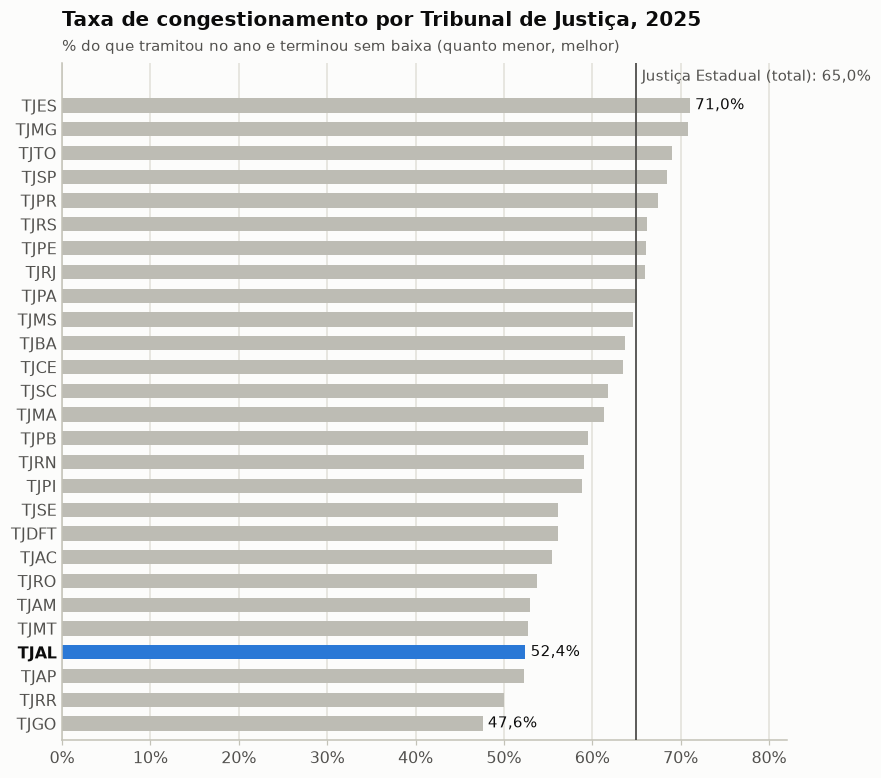

In [23]:
# Figura 1: ranking da taxa de congestionamento. Barras horizontais ordenadas porque o
# objetivo é comparar magnitudes entre 27 categorias, e os nomes ficam legíveis no eixo.
d = e25.sort_values("tc")
fig, ax = plt.subplots(figsize=(8.5, 8))
cores = np.where(d["sigla"].eq(DESTAQUE), COR["destaque"], COR["contexto"])
ax.barh(d["sigla"], d["tc"], color=cores, height=0.6, zorder=2)
ax.axvline(ref["tc"], color=COR["tinta2"], lw=1.2, zorder=3)
ax.text(ref["tc"] + 0.6, len(d) + 0.2, f"Justiça Estadual (total): {pct(ref['tc'])}",
        fontsize=9.5, color=COR["tinta2"], va="center")
# Rótulos seletivos: só o tribunal em destaque e os dois extremos.
for _, r in d[d["sigla"].isin([DESTAQUE, d["sigla"].iloc[0], d["sigla"].iloc[-1]])].iterrows():
    ax.text(r["tc"] + 0.6, r["sigla"], pct(r["tc"]), va="center", fontsize=9.5, color=COR["tinta"])
ax.set_xlim(0, 82)
ax.set_ylim(-0.7, len(d) + 0.8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
destacar_rotulo(ax)
titulo(ax, f"Taxa de congestionamento por Tribunal de Justiça, {ANO}",
       "% do que tramitou no ano e terminou sem baixa (quanto menor, melhor)")
salvar(fig, "fig1_ranking_congestionamento")
plt.show()

**Figura 1.** Há **23 pontos percentuais** de diferença entre o tribunal menos e o mais congestionado.
- **Menos congestionados:** dos 7 primeiros, 5 são de porte pequeno do Norte e Nordeste (TJRR, TJAP, TJAL, TJAM, TJRO). As exceções são o TJGO, o menor de todos, e o TJMT, ambos de porte médio.
- **Mais congestionados:** no topo estão TJES, TJMG e TJTO. **5 dos 6 tribunais de grande porte** (TJMG, TJSP, TJPR, TJRS, TJRJ) estão entre os 8 mais congestionados.
- O total da Justiça Estadual (65,0%) fica **acima da mediana dos tribunais (61,3%)**, porque o CNJ pondera pelo volume e os tribunais grandes pesam mais.

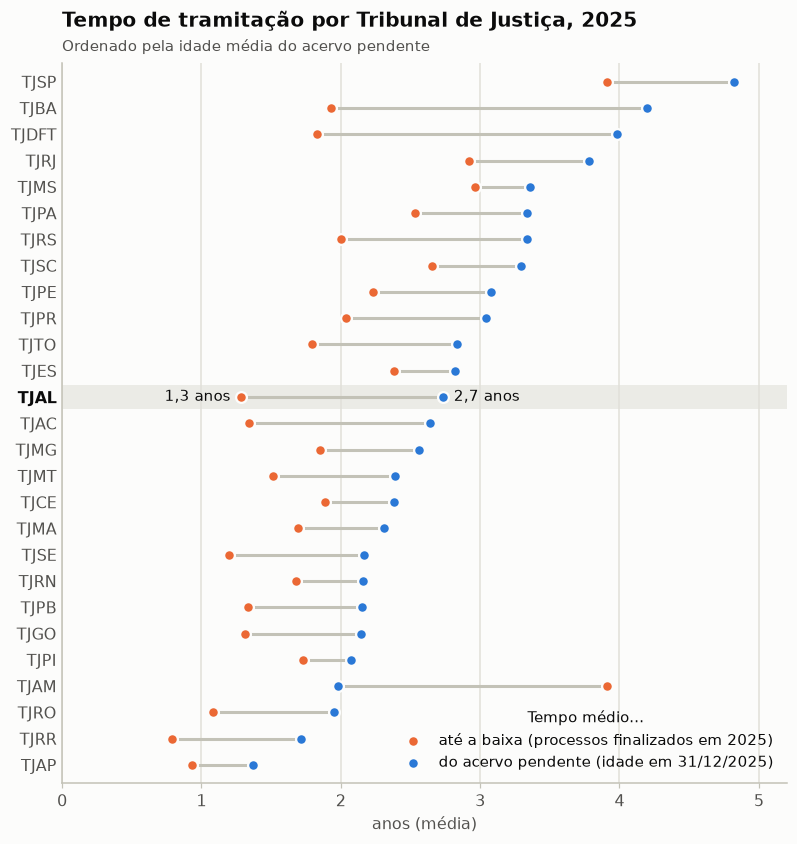

Acervo pendente mais velho que o tempo até a baixa em 26 de 27 TJs.
Medianas entre os TJs: até a baixa = 1,8 anos | acervo pendente = 2,6 anos


In [24]:
# Figura 2: dois tempos lado a lado, por tribunal (gráfico de "halteres"). Mostra a
# diferença entre os processos que TERMINARAM em 2025 e os que AINDA ESTÃO no acervo.
d = e25.sort_values("tempo_pendente").reset_index(drop=True)
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(8.5, 8.5))
linha_dest = d.index[d["sigla"] == DESTAQUE][0]
ax.axhspan(linha_dest - 0.45, linha_dest + 0.45, color=COR["grade"], alpha=0.6, lw=0, zorder=0)
ax.hlines(y, anos(d["tempo_baixa"]), anos(d["tempo_pendente"]), color=COR["eixo"], lw=2, zorder=1)
ax.scatter(anos(d["tempo_baixa"]), y, s=50, color=COR["laranja"], edgecolor=COR["fundo"], linewidth=1.5,
           zorder=3, label="até a baixa (processos finalizados em 2025)")
ax.scatter(anos(d["tempo_pendente"]), y, s=50, color=COR["destaque"], edgecolor=COR["fundo"], linewidth=1.5,
           zorder=3, label="do acervo pendente (idade em 31/12/2025)")
r = d.loc[linha_dest]
for col, desloc, ha in [("tempo_baixa", -7, "right"), ("tempo_pendente", 7, "left")]:
    ax.annotate(f"{num(anos(r[col]), 1)} anos", (anos(r[col]), linha_dest), xytext=(desloc, 0),
                textcoords="offset points", va="center", ha=ha, fontsize=9.5, color=COR["tinta"])
ax.set_yticks(y, d["sigla"])
ax.set_ylim(-0.7, len(d) - 0.3)
ax.set_xlim(0, 5.2)
ax.set_xlabel("anos (média)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
destacar_rotulo(ax)
ax.legend(loc="lower right", title="Tempo médio…", title_fontsize=9.5, fontsize=9.5)
titulo(ax, f"Tempo de tramitação por Tribunal de Justiça, {ANO}",
       "Ordenado pela idade média do acervo pendente")
salvar(fig, "fig2_tempos_baixa_pendente")
plt.show()

n_maior = int((e25["tempo_pendente"] > e25["tempo_baixa"]).sum())
print(f"Acervo pendente mais velho que o tempo até a baixa em {n_maior} de {len(e25)} TJs.")
print(f"Medianas entre os TJs: até a baixa = {num(anos(e25['tempo_baixa'].median()), 1)} anos | "
      f"acervo pendente = {num(anos(e25['tempo_pendente'].median()), 1)} anos")

**Figura 2.** Em 26 dos 27 tribunais, os processos que **continuam no acervo são mais antigos** que os que foram finalizados no ano (medianas: 2,6 contra 1,8 anos). É um efeito de seleção: os casos simples saem rápido, e ficam os difíceis, os parados e os de execução. Por isso, olhar só o tempo de quem terminou faz a Justiça parecer mais rápida do que é. A única exceção é o **TJAM**, explicada logo abaixo.

In [25]:
# 4.2 O "paradoxo" do TJAM: a exceção da Figura 2. Comparamos 2024 e 2025.
if AREA == "Estadual":
    cols = ["casos_novos", "baixados", "casos_pendentes", "suspensos", "tc", "tempo_baixa", "tempo_pendente"]
    tjam = limpo[(limpo["sigla"] == "TJAM") & limpo["ano"].isin([ANO - 1, ANO])].set_index("ano")[cols].T
    tjam["variação (%)"] = 100 * (tjam[ANO] / tjam[ANO - 1] - 1)
    display(tjam.round(1))

ano,2024,2025,variação (%)
casos_novos,667183.0,721639.0,8.2
baixados,683230.0,798968.0,16.9
casos_pendentes,970606.0,901006.0,-7.2
suspensos,368815.0,198877.0,-46.1
tc,58.7,53.0,-9.7
tempo_baixa,508.9,1427.7,180.5
tempo_pendente,1618.8,724.3,-55.3


**O paradoxo do TJAM.** Em 2025 o TJAM baixou 17% mais processos e reduziu os suspensos quase à metade (−46%). O resultado foi uma "limpeza" de processos antigos:
- a idade média do acervo **caiu pela metade** (de 4,4 para 2,0 anos);
- o tempo médio até a baixa **quase triplicou** (de 1,4 para 3,9 anos), porque os processos baixados eram justamente os mais velhos.

**Lição:** os dois indicadores de tempo podem andar em **direções opostas**. Um tribunal que ataca o estoque antigo "piora" no tempo até a baixa no curto prazo. Nunca avalie um tribunal por um indicador só.

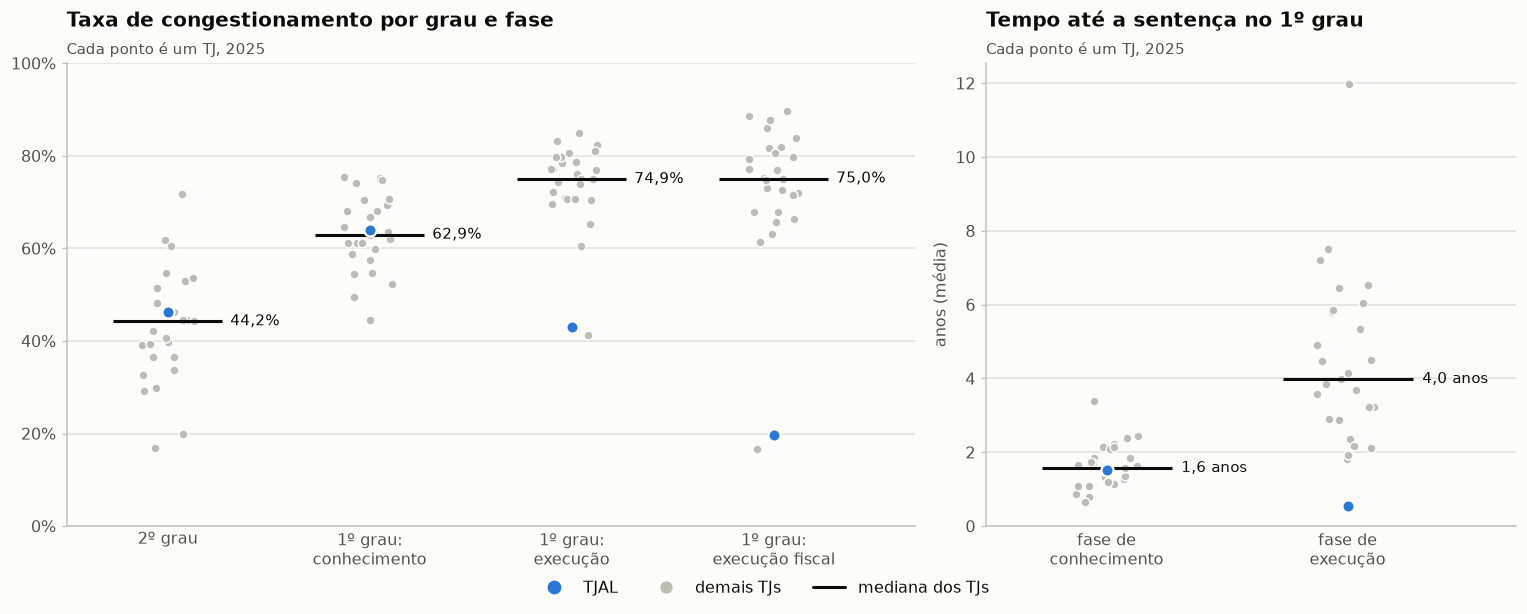

Execução mais lenta que conhecimento em 26 de 27 TJs.
Série do TJAL, tempo até a sentença na execução (dias):


ano,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
tempo_sentenca_exec_1g,1934.0,3227.0,1555.0,477.0,186.0,366.0,117.0,2133.0,267.0,199.0


In [26]:
# Figura 3: congestionamento e tempo por GRAU e FASE. O enunciado pede para "respeitar as
# diferenças entre processos": conhecimento (decidir quem tem razão) e execução (fazer
# cumprir) são etapas muito diferentes, e a execução fiscal (cobrança de dívida pública)
# é um caso à parte.
def dispersao_categorias(ax, dados, colunas, transforma=lambda v: v, fmt=pct):
    """Um ponto por tribunal em cada categoria; traço preto = mediana; azul = destaque."""
    rng = np.random.default_rng(7)  # semente fixa: o espalhamento é igual a cada execução
    eh_dest = dados["sigla"].eq(DESTAQUE).to_numpy()
    for i, col in enumerate(colunas):
        v = transforma(dados[col]).to_numpy()
        x = i + rng.uniform(-0.13, 0.13, len(v))
        ax.scatter(x[~eh_dest], v[~eh_dest], s=34, color=COR["contexto"], edgecolor=COR["fundo"], lw=1, zorder=2)
        ax.scatter([i], v[eh_dest], s=64, color=COR["destaque"], edgecolor=COR["fundo"], lw=1.5, zorder=4)
        med = np.nanmedian(v)
        ax.hlines(med, i - 0.27, i + 0.27, color=COR["tinta"], lw=2, zorder=3)
        ax.text(i + 0.31, med, fmt(med), va="center", fontsize=9.5, color=COR["tinta"])
    ax.set_xticks(range(len(colunas)), list(colunas.values()))
    ax.set_xlim(-0.5, len(colunas) - 0.3)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", length=0)


fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.6, 1]})
fases_tc = {"tc_2grau": "2º grau", "tc_conhecimento_1g": "1º grau:\nconhecimento",
            "tc_execucao_1g": "1º grau:\nexecução", "tc_exec_fiscal_1g": "1º grau:\nexecução fiscal"}
dispersao_categorias(a1, e25, fases_tc)
a1.set_ylim(0, 100)
a1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
titulo(a1, "Taxa de congestionamento por grau e fase", f"Cada ponto é um TJ, {ANO}")

fases_tp = {"tempo_sentenca_conhec_1g": "fase de\nconhecimento", "tempo_sentenca_exec_1g": "fase de\nexecução"}
dispersao_categorias(a2, e25, fases_tp, transforma=anos, fmt=lambda v: f"{num(v, 1)} anos")
a2.set_ylim(0, None)
a2.set_ylabel("anos (média)")
titulo(a2, "Tempo até a sentença no 1º grau", f"Cada ponto é um TJ, {ANO}")

legenda = [Line2D([], [], marker="o", ls="", color=COR["destaque"], markersize=8, label=DESTAQUE),
           Line2D([], [], marker="o", ls="", color=COR["contexto"], markersize=7, label="demais TJs"),
           Line2D([], [], color=COR["tinta"], lw=2, label="mediana dos TJs")]
fig.legend(handles=legenda, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout()
salvar(fig, "fig3_grau_e_fase")
plt.show()

n_exec = int((e25["tempo_sentenca_exec_1g"] > e25["tempo_sentenca_conhec_1g"]).sum())
print(f"Execução mais lenta que conhecimento em {n_exec} de {len(e25)} TJs.")
print(f"Série do {DESTAQUE}, tempo até a sentença na execução (dias):")
display(limpo[(limpo["sigla"] == DESTAQUE) & (limpo["ano"] >= 2016)]
        .set_index("ano")["tempo_sentenca_exec_1g"].round(0).to_frame().T)

**Figura 3.** O gargalo está na **execução**, não no julgamento:
- No 1º grau, a TC mediana é de 62,9% no conhecimento, 74,9% na execução e 75,0% na execução fiscal. O 2º grau é bem menos congestionado (44,2%).
- O tempo até a sentença na execução (mediana de 4,0 anos) é **duas vezes e meia** o tempo na fase de conhecimento (1,6 ano), e é maior em 26 dos 27 TJs.

O TJAL destoa nos dois painéis: tem a 2ª menor TC na execução fiscal (atrás só do TJAM) e é o único TJ com execução mais rápida que o conhecimento. A seção 4.4 mostra que isso vem de ondas de execuções fiscais que entram e saem no mesmo ano. Mesmo assim, a série do TJAL no tempo até a sentença na execução oscila de forma pouco plausível (117 → 2.133 → 267 dias em três anos seguidos). Antes de usar esse número como conclusão, vale **confirmar com o tribunal**.

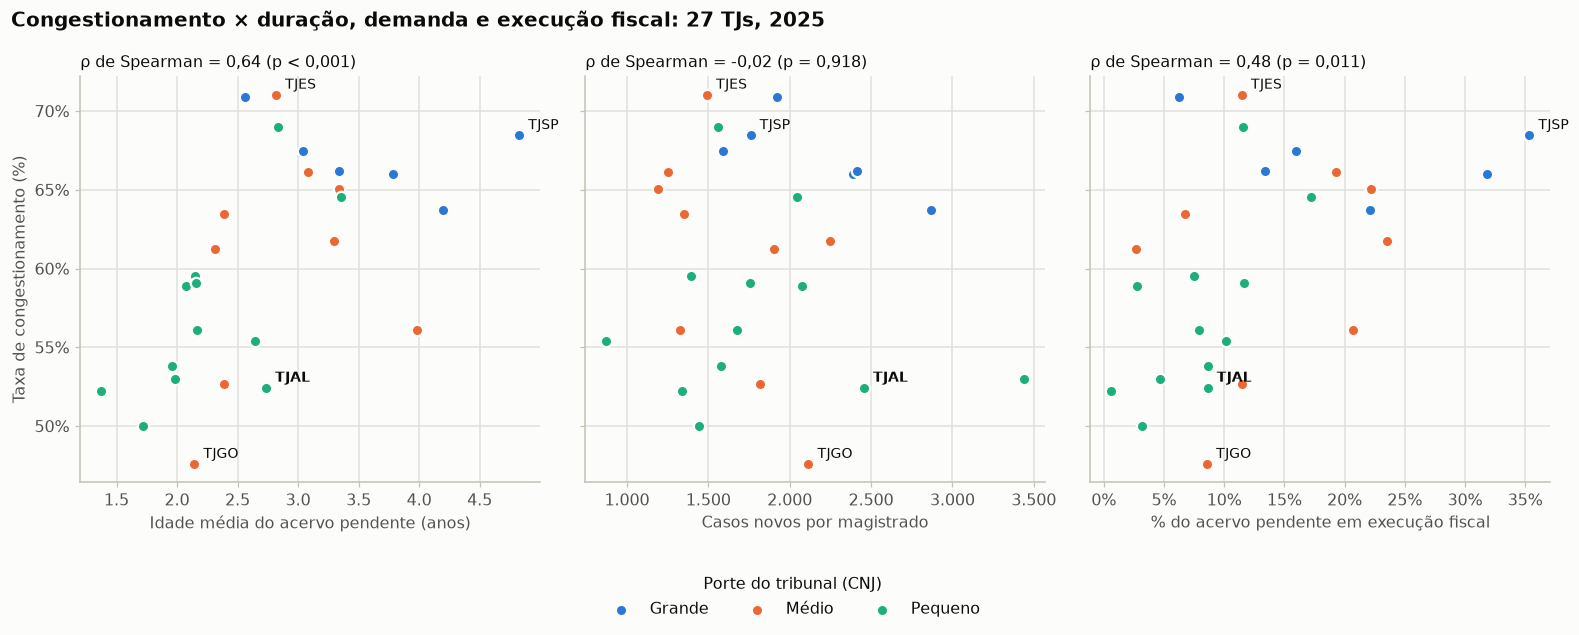

In [27]:
# Figura 4: o que anda junto com o congestionamento? Gráficos de dispersão, um por fator,
# todos com a TC no eixo y (mesma escala). Cor = porte do tribunal.
# Usamos a correlação de SPEARMAN (por postos): com só 27 pontos e tribunais muito
# desiguais (TJSP vs. TJRR), a de Pearson seria dominada por 1 ou 2 extremos.
# (A carga de trabalho por magistrado fica só na tabela: ela contém o próprio acervo, então
#  a correlação com a TC seria em parte "a TC explicando a TC".)
pares = [
    ("tempo_pendente", "Idade média do acervo pendente (anos)", anos),
    ("casos_novos_por_mag", "Casos novos por magistrado", None),
    ("pct_exec_fiscal", "% do acervo pendente em execução fiscal", None),
]
fig, axs = plt.subplots(1, 3, figsize=(14.5, 5), sharey=True)
rotular = {DESTAQUE, e25.loc[e25["tc"].idxmax(), "sigla"], e25.loc[e25["tc"].idxmin(), "sigla"],
           e25.loc[e25["casos_novos"].idxmax(), "sigla"]}
for ax, (col, rotulo, f) in zip(axs, pares):
    xval = f(e25[col]) if f else e25[col]
    for porte, cor in COR_PORTE.items():
        m = e25["porte"] == porte
        ax.scatter(xval[m], e25.loc[m, "tc"], s=55, color=cor, edgecolor=COR["fundo"], lw=1.5, zorder=3, label=porte)
    for s in rotular:
        i = e25.index[e25["sigla"] == s][0]
        ax.annotate(s, (xval[i], e25.at[i, "tc"]), xytext=(6, 4), textcoords="offset points", fontsize=9,
                    fontweight="bold" if s == DESTAQUE else "normal", color=COR["tinta"])
    rho, p = stats.spearmanr(e25[col], e25["tc"], nan_policy="omit")
    ax.set_title(f"ρ de Spearman = {num(rho, 2)} ({p_texto(p)})", loc="left", fontsize=10.5)
    ax.set_xlabel(rotulo)
    if col == "casos_novos_por_mag":
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: num(v)))
    if col == "pct_exec_fiscal":
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
axs[0].set_ylabel("Taxa de congestionamento (%)")
axs[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
fig.legend(*axs[0].get_legend_handles_labels(), title="Porte do tribunal (CNJ)", loc="lower center",
           ncol=3, bbox_to_anchor=(0.5, -0.15))
fig.suptitle(f"Congestionamento × duração, demanda e execução fiscal: 27 TJs, {ANO}",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
salvar(fig, "fig4_dispersao_fatores")
plt.show()

In [28]:
# 4.3 Tabela de correlações (Spearman) para os dois alvos: congestionamento e idade do acervo.
# ⚠ = correlação em parte MECÂNICA: o indicador é calculado com pendentes e/ou baixados,
#     os mesmos números da fórmula da TC. Não serve como "explicação".
CANDIDATOS = {
    "tempo_pendente": "Idade média do acervo pendente",
    "tempo_baixa": "Tempo médio até a baixa",
    "casos_novos_por_mag": "Casos novos por magistrado",
    "casos_novos_100mil_hab": "Casos novos por 100 mil habitantes",
    "ipm": "Produtividade dos magistrados (IPM)",
    "forca_trabalho_por_mag": "Força de trabalho por magistrado",
    "despesa_por_habitante": "Despesa por habitante",
    "pct_suspensos": "% do acervo suspenso/sobrestado",
    "pct_exec_fiscal": "% do acervo em execução fiscal",
    "carga_trabalho_mag": "Carga de trabalho por magistrado ⚠",
    "ipc_jus": "IPC-Jus, eficiência ⚠",
}
linhas = []
for col, rotulo in CANDIDATOS.items():
    linha = {"fator": rotulo}
    for alvo, nome in [("tc", "TC"), ("tempo_pendente", "idade do acervo")]:
        if col == alvo:
            linha[f"ρ com {nome}"], linha[f"p ({nome})"] = np.nan, np.nan
            continue
        rho, p = stats.spearmanr(e25[col], e25[alvo], nan_policy="omit")
        linha[f"ρ com {nome}"], linha[f"p ({nome})"] = rho, p
    linhas.append(linha)
correl = pd.DataFrame(linhas).set_index("fator")
display(correl.round(3))
# Com 27 tribunais, |ρ| precisa passar de ~0,38 para ter p < 0,05. E testamos 11 fatores:
# por puro acaso, esperaríamos ~0,5 "falso positivo" a 5%. Ler com cautela.

,ρ com TC,p (TC),ρ com idade do acervo,p (idade do acervo)
fator,,,,
Idade média do acervo pendente,0.64,0.00,NaN,NaN
Tempo médio até a baixa,0.68,0.00,0.69,0.00
Casos novos por magistrado,-0.02,0.92,0.10,0.61
Casos novos por 100 mil habitantes,-0.24,0.23,0.06,0.76
Produtividade dos magistrados (IPM),-0.06,0.78,0.16,0.42
Força de trabalho por magistrado,-0.22,0.27,-0.10,0.61
Despesa por habitante,-0.18,0.36,0.06,0.77
% do acervo suspenso/sobrestado,-0.18,0.37,-0.03,0.87
% do acervo em execução fiscal,0.48,0.01,0.87,0.00


**Figura 4 e tabela de correlações: o achado central.**
- **Congestionamento e duração andam juntos.** A TC tem ρ = 0,64 com a idade do acervo e ρ = 0,68 com o tempo até a baixa. Tribunais entupidos também são lentos.
- **A demanda do ano não explica o congestionamento.** Casos novos por magistrado (ρ = −0,02), casos novos por habitante (ρ = −0,24), produtividade dos magistrados (ρ = −0,06), força de trabalho por magistrado e despesa por habitante: nenhum tem correlação relevante. O TJAL, por exemplo, recebe *mais* casos por magistrado que a maioria e ainda assim é dos menos congestionados.
- **O que mais se associa é a composição do estoque.** A % do acervo em execução fiscal tem ρ = 0,48 com a TC e **ρ = 0,87 com a idade do acervo**, a correlação mais forte da tabela. Com 11 fatores testados, a de 0,48 (p = 0,01) pede cautela; a de 0,87 (p < 0,001) é robusta.
- A carga de trabalho também correlaciona (ρ = 0,44), mas é **circular**: ela inclui o próprio acervo no numerador. O mesmo vale para o IPC-Jus.
- **Interpretação:** o congestionamento é um fenômeno de **estoque** (acervo acumulado ao longo de anos, com muita execução fiscal antiga), não de **fluxo** (o que entra no ano).

### 4.4 Execução fiscal: o processo que distorce a comparação
A execução fiscal é a cobrança judicial de dívidas com o poder público, como IPTU e ISS. Ela chega em massa, muitas vezes sem bens a penhorar, e pode ficar parada por anos. Por isso o CNJ publica a TC "com e sem" execução fiscal. Seguindo o enunciado ("respeitar as diferenças entre processos"), comparamos as duas versões.

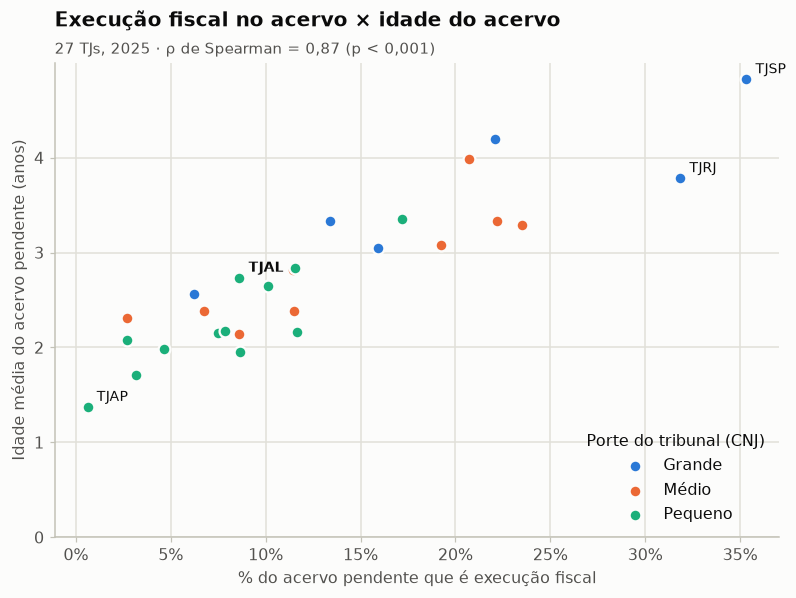

porte,Grande,Médio,Pequeno
% do acervo em execução fiscal (mediana),19.0,11.5,8.2


In [29]:
# Figura 5: peso da execução fiscal no acervo × idade média do acervo.
fig, ax = plt.subplots(figsize=(8.5, 5.6))
for porte, cor in COR_PORTE.items():
    m = e25["porte"] == porte
    ax.scatter(e25.loc[m, "pct_exec_fiscal"], anos(e25.loc[m, "tempo_pendente"]), s=60, color=cor,
               edgecolor=COR["fundo"], lw=1.5, zorder=3, label=porte)
# Rótulos seletivos: o destaque e os extremos do eixo x.
rotular = ({DESTAQUE} | set(e25.nlargest(2, "pct_exec_fiscal")["sigla"])
           | set(e25.nsmallest(1, "pct_exec_fiscal")["sigla"]))
for s in rotular:
    i = e25.index[e25["sigla"] == s][0]
    ax.annotate(s, (e25.at[i, "pct_exec_fiscal"], anos(e25.at[i, "tempo_pendente"])), xytext=(6, 4),
                textcoords="offset points", fontsize=9, fontweight="bold" if s == DESTAQUE else "normal")
rho, p = stats.spearmanr(e25["pct_exec_fiscal"], e25["tempo_pendente"])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_xlabel("% do acervo pendente que é execução fiscal")
ax.set_ylabel("Idade média do acervo pendente (anos)")
ax.set_ylim(0, None)
ax.legend(title="Porte do tribunal (CNJ)", loc="lower right")
titulo(ax, "Execução fiscal no acervo × idade do acervo",
       f"27 TJs, {ANO} · ρ de Spearman = {num(rho, 2)} ({p_texto(p)})")
salvar(fig, "fig5_execucao_fiscal_idade_acervo")
plt.show()
display(e25.groupby("porte")["pct_exec_fiscal"].median().rename("% do acervo em execução fiscal (mediana)")
        .loc[["Grande", "Médio", "Pequeno"]].round(1).to_frame().T)

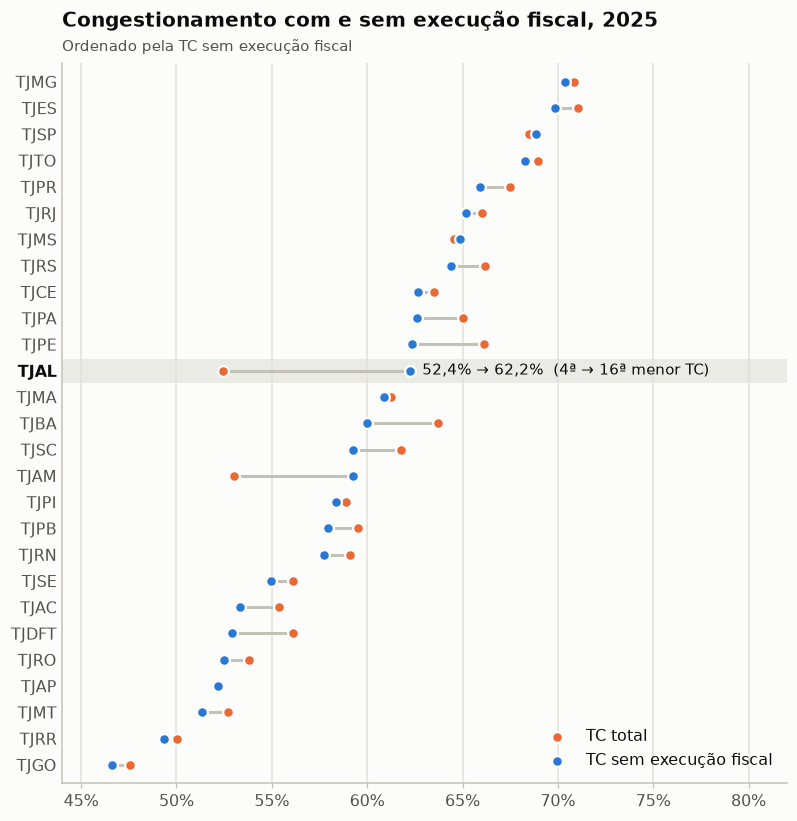

,tc,tc_sem_exec_fiscal,tc_exec_fiscal_1g,posição TC total,posição TC sem EF,posições perdidas sem EF
sigla,,,,,,
TJAL,52.4,62.2,19.6,4.0,16.0,12.0
TJAM,53.0,59.3,16.7,6.0,12.0,6.0
TJCE,63.5,62.7,76.9,16.0,19.0,3.0
TJMS,64.6,64.9,63.2,18.0,21.0,3.0
TJRJ,66.0,65.2,67.9,20.0,22.0,2.0


TJAL: execução fiscal, 2016–2025


,casos_novos,casos_novos_exec_fiscal_1g,baixados,baixados_exec_fiscal_1g,pendentes_exec_fiscal_1g,tc,tc_sem_exec_fiscal,tc_exec_fiscal_1g
ano,,,,,,,,
2016,149551.0,11612.0,117998.0,11806.0,131464.0,82.6,80.1,91.8
2017,217732.0,50365.0,179796.0,18211.0,163618.0,76.9,72.9,90.0
2018,146885.0,2706.0,225522.0,45747.0,117887.0,70.1,69.6,72.0
2019,206211.0,47697.0,252891.0,55775.0,109405.0,65.9,65.8,66.2
2020,249318.0,117545.0,254199.0,121847.0,103246.0,64.7,73.3,45.9
2021,206930.0,49017.0,183990.0,50699.0,101715.0,72.9,74.7,66.7
2022,508856.0,335469.0,501022.0,332339.0,105268.0,50.4,70.6,24.1
2023,232561.0,8077.0,247222.0,24092.0,89505.0,67.1,65.0,78.8
2024,474307.0,211047.0,500601.0,242594.0,57530.0,49.5,62.7,19.2


In [30]:
# Figura 6: TC total × TC sem execução fiscal, por tribunal. Mostra quanto do resultado de
# cada tribunal depende da execução fiscal. Gráfico de pontos: aqui importa a POSIÇÃO, não o
# comprimento, então o eixo não precisa começar em zero.
d = e25.sort_values("tc_sem_exec_fiscal").reset_index(drop=True)
y = np.arange(len(d))
linha_dest = d.index[d["sigla"] == DESTAQUE][0]
fig, ax = plt.subplots(figsize=(8.5, 8.5))
ax.axhspan(linha_dest - 0.45, linha_dest + 0.45, color=COR["grade"], alpha=0.6, lw=0, zorder=0)
ax.hlines(y, d["tc"], d["tc_sem_exec_fiscal"], color=COR["eixo"], lw=2, zorder=1)
ax.scatter(d["tc"], y, s=50, color=COR["laranja"], edgecolor=COR["fundo"], linewidth=1.5, zorder=3,
           label="TC total")
ax.scatter(d["tc_sem_exec_fiscal"], y, s=50, color=COR["destaque"], edgecolor=COR["fundo"], linewidth=1.5,
           zorder=3, label="TC sem execução fiscal")
pos_total = int(e25["tc"].rank(method="min")[e25["sigla"] == DESTAQUE].iloc[0])
pos_sem = int(e25["tc_sem_exec_fiscal"].rank(method="min")[e25["sigla"] == DESTAQUE].iloc[0])
r = d.loc[linha_dest]
ax.annotate(f"{pct(r['tc'])} → {pct(r['tc_sem_exec_fiscal'])}  ({pos_total}ª → {pos_sem}ª menor TC)",
            (max(r["tc"], r["tc_sem_exec_fiscal"]), linha_dest), xytext=(8, 0), textcoords="offset points",
            va="center", fontsize=9.5)
ax.set_yticks(y, d["sigla"])
ax.set_ylim(-0.7, len(d) - 0.3)
ax.set_xlim(44, 82)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
destacar_rotulo(ax)
ax.legend(loc="lower right")
titulo(ax, f"Congestionamento com e sem execução fiscal, {ANO}", "Ordenado pela TC sem execução fiscal")
salvar(fig, "fig6_tc_com_sem_execucao_fiscal")
plt.show()

# Quem mais "ganha posições" por causa da execução fiscal?
mud = e25.set_index("sigla")[["tc", "tc_sem_exec_fiscal", "tc_exec_fiscal_1g"]].assign(
    **{"posição TC total": e25.set_index("sigla")["tc"].rank(method="min"),
       "posição TC sem EF": e25.set_index("sigla")["tc_sem_exec_fiscal"].rank(method="min")})
mud["posições perdidas sem EF"] = mud["posição TC sem EF"] - mud["posição TC total"]
display(mud.sort_values("posições perdidas sem EF", ascending=False).head(5).round(1))

# A onda de execuções fiscais no TJAL: casos novos, baixados e acervo de execução fiscal.
cols = ["casos_novos", "casos_novos_exec_fiscal_1g", "baixados", "baixados_exec_fiscal_1g",
        "pendentes_exec_fiscal_1g", "tc", "tc_sem_exec_fiscal", "tc_exec_fiscal_1g"]
print(f"{DESTAQUE}: execução fiscal, 2016–{ANO}")
display(limpo[(limpo["sigla"] == DESTAQUE) & (limpo["ano"] >= 2016)].set_index("ano")[cols].round(1))

**Figuras 5 e 6.**
- **Execução fiscal envelhece o acervo.** Quanto maior a fatia de execução fiscal no estoque, mais velho ele é (ρ = 0,87). TJSP e TJRJ têm cerca de um terço do acervo em execução fiscal e estão entre os acervos mais antigos. O TJAP tem quase nenhuma e tem o acervo mais novo. A fatia mediana é de 19,0% nos tribunais grandes, 11,5% nos médios e 8,2% nos pequenos, o que ajuda a explicar a diferença por porte (Figura 7).
- **No TJAL, a execução fiscal muda o retrato.** Na TC total o TJAL é o 4º melhor do país (52,4%). **Sem a execução fiscal, cai para 62,2%, o 16º lugar**, perto da mediana. A TC da execução fiscal no TJAL é de apenas 19,6%, contra 75,0% na mediana dos TJs. O TJAM mostra o mesmo padrão.
- **Por quê?** Em 2022, 2024 e 2025 o TJAL recebeu ondas de execuções fiscais e as baixou no mesmo ano (em 2022: 335 mil novas e 332 mil baixadas). Nesses três anos a TC total ficou abaixo de 53%. Em 2023, sem a onda, voltou a 67,1%. O acervo de execução fiscal do TJAL caiu de 131 mil (2016) para 43,5 mil processos (2025).
- **Hipótese para o grupo investigar:** mutirões ou extinção em massa de execuções fiscais de baixo valor, incentivada desde 2024 pela Resolução CNJ nº 547/2024. Os dados mostram *o que* aconteceu, não *por quê*. Vale confirmar com o TJAL ou em notícias oficiais.

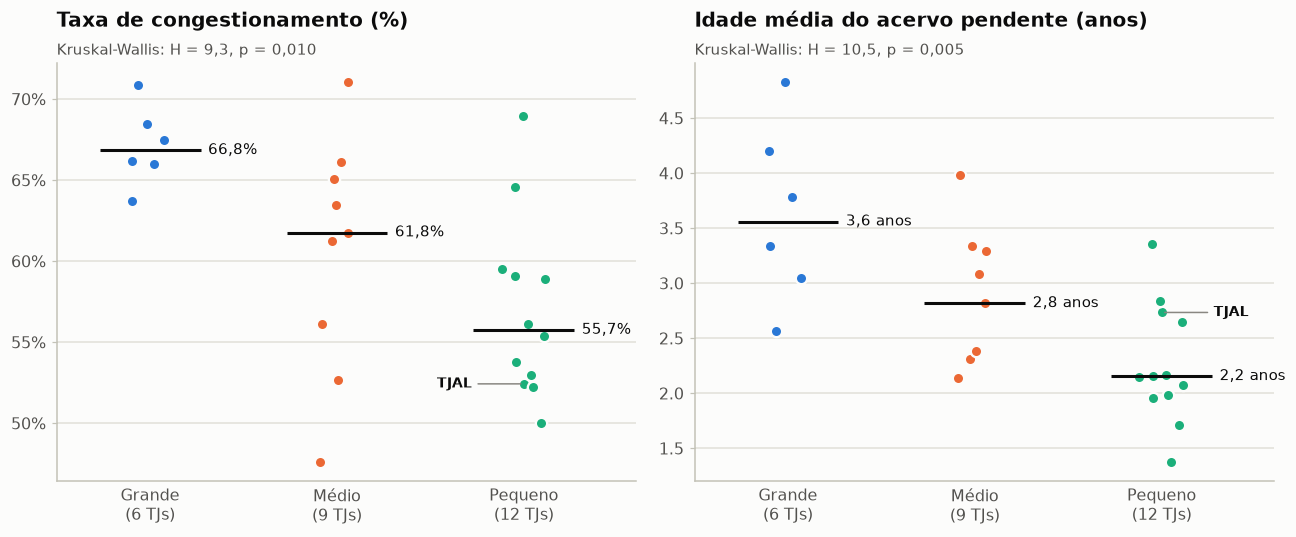

,tc,tc_sem_exec_fiscal,tempo_pendente,tempo_baixa,casos_novos_por_mag,pct_exec_fiscal
porte,,,,,,
Grande,66.8,65.5,1300.0,737.9,2154.4,19.0
Médio,61.8,60.9,1029.0,689.4,1491.5,11.5
Pequeno,55.7,57.9,787.0,489.4,1626.7,8.2


In [31]:
# Figura 7: porte do tribunal. O CNJ classifica os TJs em Grande, Médio e Pequeno porte
# (combinando despesa, processos e pessoal). Testamos se o porte separa os grupos com
# Kruskal-Wallis (versão não paramétrica da ANOVA: não exige distribuição normal, o que
# importa com grupos de 5 a 13 tribunais).
ordem = ["Grande", "Médio", "Pequeno"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5))
# "lado" = de que lado do ponto vai o rótulo do destaque (escolhido para não colidir com nada).
for ax, col, rot, f, fmt, lado in [(a1, "tc", "Taxa de congestionamento (%)", lambda v: v, pct, -1),
                                    (a2, "tempo_pendente", "Idade média do acervo pendente (anos)", anos,
                                     lambda v: f"{num(v, 1)} anos", 1)]:
    rng = np.random.default_rng(3)
    for i, porte in enumerate(ordem):
        g = e25[e25["porte"] == porte]
        v = f(g[col]).to_numpy()
        # Espalhamento horizontal só para os pontos não se sobreporem; o destaque fica no centro
        # (x = i), para o rótulo apontar exatamente para ele.
        x = i + rng.uniform(-0.12, 0.12, len(v))
        x[g["sigla"].eq(DESTAQUE).to_numpy()] = i
        ax.scatter(x, v, s=55, color=COR_PORTE[porte], edgecolor=COR["fundo"], lw=1.5, zorder=3)
        med = np.median(v)
        ax.hlines(med, i - 0.27, i + 0.27, color=COR["tinta"], lw=2, zorder=4)
        ax.text(i + 0.31, med, fmt(med), va="center", fontsize=9.5)
        if DESTAQUE in g["sigla"].values:
            vd = f(g.loc[g["sigla"] == DESTAQUE, col]).iloc[0]
            ax.annotate(DESTAQUE, (i, vd), xytext=(34 * lado, 0), textcoords="offset points", va="center",
                        ha="left" if lado > 0 else "right",
                        fontsize=9, fontweight="bold", arrowprops=dict(arrowstyle="-", color=COR["mudo"], lw=1))
    h, p = stats.kruskal(*[e25.loc[e25["porte"] == pt, col] for pt in ordem])
    n = e25["porte"].value_counts()
    ax.set_xticks(range(3), [f"{pt}\n({n[pt]} TJs)" for pt in ordem])
    ax.set_xlim(-0.5, 2.6)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", length=0)
    titulo(ax, rot, f"Kruskal-Wallis: H = {num(h, 1)}, {p_texto(p)}")
a1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
fig.tight_layout()
salvar(fig, "fig7_porte")
plt.show()
display(e25.groupby("porte")[["tc", "tc_sem_exec_fiscal", "tempo_pendente", "tempo_baixa", "casos_novos_por_mag",
                              "pct_exec_fiscal"]].median().loc[ordem].round(1))

**Figura 7.** O porte separa os grupos com clareza:
- A TC mediana é de 66,8% nos tribunais **grandes**, 61,8% nos médios e 55,7% nos pequenos (Kruskal-Wallis, p = 0,010).
- O acervo pendente tem 3,6 anos de idade média nos grandes e 2,2 anos nos pequenos (p = 0,005).

Os grandes recebem um pouco mais de casos por magistrado, mas essa variável não acompanha a TC entre tribunais (Figura 4). Uma explicação mais coerente com os dados é o **estoque histórico**: o acervo dos grandes tem mais que o dobro da fatia de execução fiscal dos pequenos (19,0% contra 8,2%). Mas a execução fiscal não explica tudo: **mesmo sem ela, a diferença persiste** (TC mediana de 65,5% nos grandes contra 57,9% nos pequenos). O TJAL tem a 3ª menor TC entre os 12 tribunais pequenos.

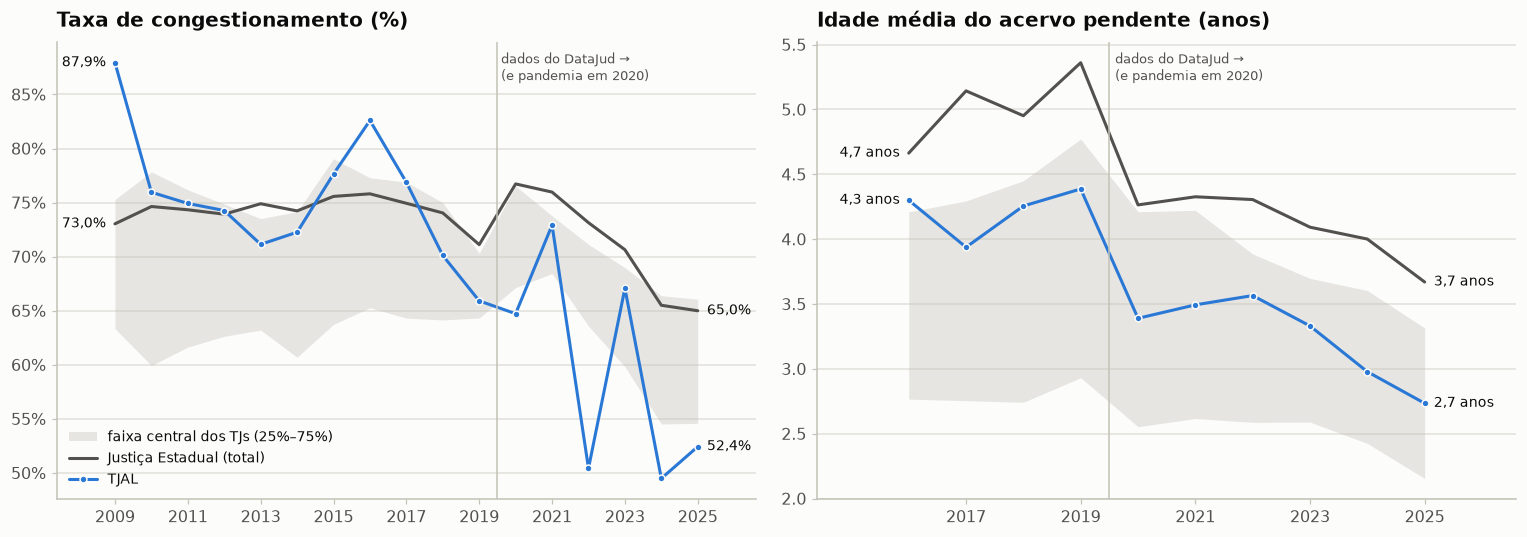

Justiça Estadual (total do CNJ), série 2009–2025:


ano,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
tc,73.03,74.63,74.33,73.92,74.89,74.23,75.57,75.81,74.93,74.04,71.11,76.72,75.97,73.14,70.64,65.50,64.99
tc_sem_exec_fiscal,65.73,65.67,65.92,65.47,67.10,65.01,66.93,67.52,66.01,65.80,63.36,72.22,70.69,67.82,64.24,63.13,63.85
tempo_pendente,NaN,NaN,NaN,NaN,NaN,NaN,2174.02,1703.31,1878.60,1808.61,1957.91,1557.49,1580.35,1572.51,1494.73,1461.32,1340.33
tempo_pendente_anos,NaN,NaN,NaN,NaN,NaN,NaN,5.95,4.66,5.14,4.95,5.36,4.26,4.33,4.31,4.09,4.00,3.67


TJAL, série 2016–2025:


,casos_novos,baixados,casos_pendentes,iad,tc,tc_sem_exec_fiscal,tempo_baixa,tempo_pendente
ano,,,,,,,,
2016,149551.0,117998.0,559781.0,78.9,82.6,80.1,1200.7,1570.6
2017,217732.0,179796.0,597717.0,82.6,76.9,72.9,1193.5,1438.3
2018,146885.0,225522.0,528953.0,153.5,70.1,69.6,1226.0,1554.4
2019,206211.0,252891.0,488922.0,122.6,65.9,65.8,863.0,1602.3
2020,249318.0,254199.0,466395.0,102.0,64.7,73.3,536.4,1238.1
2021,206930.0,183990.0,495237.0,88.9,72.9,74.7,729.7,1276.0
2022,508856.0,501022.0,509580.0,98.5,50.4,70.6,364.7,1302.2
2023,232561.0,247222.0,503423.0,106.3,67.1,65.0,975.6,1216.6
2024,474307.0,500601.0,490385.0,105.5,49.5,62.7,570.7,1087.8


Posição do TJAL em 2009 (1 = MAIS congestionado): 1º de 27


In [32]:
# Figura 8: evolução no tempo. Dois gráficos separados (um eixo cada) porque são medidas
# diferentes. A faixa cinza mostra onde está a "metade do meio" dos TJs (do 25º ao 75º
# percentil), o que dá contexto sem desenhar 27 linhas embaralhadas.
serie = limpo[limpo["justica"] == AREA]
ref_serie = totais_limpo[totais_limpo["justica"] == AREA].set_index("ano")
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
config = [(axs[0], "tc", 2009, "Taxa de congestionamento (%)", lambda v: v, pct),
          (axs[1], "tempo_pendente", 2016, "Idade média do acervo pendente (anos)", anos,
           lambda v: f"{num(v, 1)} anos")]
for ax, col, ini, rot, f, fmt in config:
    s = serie[serie["ano"] >= ini]
    q = s.groupby("ano")[col].quantile([0.25, 0.75]).unstack()
    ax.fill_between(q.index, f(q[0.25]), f(q[0.75]), color=COR["contexto"], alpha=0.35, lw=0,
                    label="faixa central dos TJs (25%–75%)")
    rs = ref_serie.loc[ref_serie.index >= ini, col]
    ax.plot(rs.index, f(rs), color=COR["tinta2"], label="Justiça Estadual (total)")
    td = s[s["sigla"] == DESTAQUE].set_index("ano")[col]
    ax.plot(td.index, f(td), color=COR["destaque"], marker="o", markersize=4.5,
            markeredgecolor=COR["fundo"], label=DESTAQUE)
    # Valores no início e no fim das duas linhas principais (rótulos seletivos).
    for serie_lin, cor in [(td, COR["destaque"]), (rs, COR["tinta2"])]:
        serie_lin = serie_lin.dropna()
        ax.annotate(fmt(f(serie_lin.iloc[-1])), (serie_lin.index[-1], f(serie_lin.iloc[-1])), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9, color=COR["tinta"])
        ax.annotate(fmt(f(serie_lin.iloc[0])), (serie_lin.index[0], f(serie_lin.iloc[0])), xytext=(-6, 0),
                    textcoords="offset points", va="center", ha="right", fontsize=9, color=COR["tinta"])
    ax.axvline(2019.5, color=COR["eixo"], lw=1)
    ax.text(2019.6, 0.98, "dados do DataJud →\n(e pandemia em 2020)", transform=ax.get_xaxis_transform(),
            fontsize=8.5, color=COR["tinta2"], va="top")
    ax.set_xlim(ini - 1.6, ANO + 1.6)
    ax.set_xticks(list(range(ANO, ini - 1, -2))[::-1])
    ax.grid(axis="x", visible=False)
    titulo(ax, rot)
axs[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
axs[0].legend(loc="lower left", fontsize=9)
fig.tight_layout()
salvar(fig, "fig8_serie_historica")
plt.show()

print(f"Justiça Estadual (total do CNJ), série 2009–{ANO}:")
display(ref_serie[["tc", "tc_sem_exec_fiscal", "tempo_pendente"]].assign(
    tempo_pendente_anos=lambda t: anos(t["tempo_pendente"])).round(2).T)
cols = ["casos_novos", "baixados", "casos_pendentes", "iad", "tc", "tc_sem_exec_fiscal", "tempo_baixa", "tempo_pendente"]
print(f"{DESTAQUE}, série 2016–{ANO}:")
display(limpo[(limpo["sigla"] == DESTAQUE) & (limpo["ano"] >= 2016)].set_index("ano")[cols].round(1))
pos09 = limpo.query("justica == @AREA and ano == 2009").set_index("sigla")["tc"].rank(method="min", ascending=False)
print(f"Posição do {DESTAQUE} em 2009 (1 = MAIS congestionado): {int(pos09[DESTAQUE])}º de {len(pos09)}")

**Figura 8.**
- **Justiça Estadual:** de 2009 a 2021 a TC oscilou entre 71% e 77%. Desde 2022 cai todo ano e chegou a 65,0% em 2025, o menor valor da série. Na era DataJud, a idade média do acervo caiu de 4,3 anos (2020) para 3,7 anos (2025).
- **Quebra em 2020:** coincidem a pandemia e a troca da fonte de dados (digitação manual → DataJud). A variação de 2019 para 2020 (ex.: a idade do acervo "caiu" de 5,4 para 4,3 anos) não deve ser lida como mudança real de desempenho.
- **TJAL:** em 2009 era o tribunal **mais congestionado do país** (87,9%). Em 2025 tem a 4ª menor TC (52,4%). A idade do acervo caiu de 3,4 anos (2020) para 2,7 anos (2025). Os "vales" de 2022 e 2024–2025 na TC são as ondas de execução fiscal da seção 4.4. Sem a execução fiscal, a TC do TJAL também melhorou, mas menos: de 73,3% em 2020 para 62,2% em 2025.

## 5. O que encontramos

1. **A variação entre tribunais é grande.** Em 2025, a TC dos TJs vai de **47,6% (TJGO) a 71,0% (TJES)**, e a idade média do acervo pendente vai de **1,4 a 4,8 anos**. Os números da base limpa batem com o relatório oficial do CNJ.
2. **O que fica no acervo é mais velho que o que sai.** Em 26 dos 27 TJs, o acervo pendente é mais antigo que o tempo até a baixa (medianas: 2,6 contra 1,8 anos). Olhar só os processos finalizados faz a Justiça parecer mais rápida do que é.
3. **O gargalo é a execução, não o julgamento.** O congestionamento mediano é de 74,9% na execução contra 62,9% no conhecimento. A sentença na execução leva 4,0 anos contra 1,6 ano (mediana) e é mais lenta em 26 dos 27 TJs.
4. **Acúmulo e duração andam juntos.** A TC tem correlação de Spearman de 0,64 com a idade do acervo e de 0,68 com o tempo até a baixa.
5. **A demanda do ano não explica o congestionamento; a composição do estoque, sim.** Casos novos por magistrado e por habitante, produtividade, força de trabalho e despesa por habitante não se correlacionam com a TC. Já a fatia de **execução fiscal** no acervo tem ρ = 0,87 com a idade do acervo e ρ = 0,48 com a TC. O congestionamento é um fenômeno de **estoque histórico**, não de fluxo anual.
6. **O porte importa.** Os tribunais grandes são mais congestionados (66,8% contra 55,7% nos pequenos) e têm acervo mais antigo (3,6 contra 2,2 anos). As diferenças são significativas (Kruskal-Wallis). Os grandes também carregam mais execução fiscal (19,0% do acervo, contra 8,2%), mas a diferença de TC persiste mesmo sem ela (65,5% contra 57,9%).
7. **Os indicadores podem se contradizer.** No TJAM, ao "limpar" processos antigos em 2025, a idade do acervo caiu pela metade e o tempo até a baixa quase triplicou. Avaliar um tribunal exige olhar mais de um indicador, e separar a execução fiscal.
8. **TJAL, de pior a 4º melhor, com ressalva.** Em 2009 era o tribunal mais congestionado do país (87,9%); em 2025 tem a 4ª menor TC (52,4%) e o menor tempo até a sentença. Mas a vantagem vem sobretudo da **execução fiscal**: ondas de execuções que entram e são baixadas no mesmo ano (TC da execução fiscal de 19,6%, contra 75,0% na mediana). **Sem a execução fiscal, o TJAL cai para o 16º lugar (62,2%)**, perto da mediana, e a idade do acervo também é mediana (2,7 anos, 15º de 27). A causa das ondas é uma hipótese a confirmar com o tribunal.

## 6. Limitações
- **Dados agregados e poucos pontos:** são 27 tribunais. Correlação não é causalidade, os testes têm pouco poder e, com 11 fatores testados, algum resultado pode ser acaso. Conclusões sobre tribunais não valem automaticamente para processos individuais (falácia ecológica).
- **Só médias de tempo:** as medianas não estão disponíveis, e a média é puxada por poucos processos muito antigos.
- **Os tempos medem coisas diferentes** (até a baixa, até a sentença, idade do acervo) e, segundo o CNJ, não podem ser somados.
- **Quebra na série em 2020:** até 2019 os dados eram digitados à mão; desde 2020 vêm do DataJud. Junto veio a pandemia.
- **Indicadores reagem a ações administrativas** (saneamento de acervo, ondas de execução fiscal), como mostram o TJAM em 2025 e o TJAL em 2022–2025. Uma TC baixa não significa, por si só, que um processo comum novo será resolvido rápido. Por isso olhamos também a TC sem execução fiscal.
- **A TC sem execução fiscal é calculada por nós** (pendentes e baixados menos os de execução fiscal do 1º grau). A fórmula reproduz exatamente a série oficial da Figura 249 para o total da Justiça Estadual; para cada tribunal, é a mesma conta.
- **O porte é uma classificação do CNJ** que mistura despesa, processos e pessoal; não mede só tamanho.
- **O recorte é só a Justiça Estadual.** O código permite trocar `AREA` (ex.: `"Trabalho"`) e refazer tudo, mas os achados não se transferem automaticamente.

## 7. Qual modelo de *machine learning* faria sentido (sem treinar)

### Recomendação principal: regressão com *Gradient Boosting* em painel tribunal × ano
Exemplos: LightGBM, XGBoost ou o `HistGradientBoostingRegressor` do scikit-learn.

| Item | Proposta |
|---|---|
| **Pergunta que o modelo responde** | Dado o perfil de um tribunal (demanda, estrutura, composição do acervo), qual congestionamento esperar? E, principalmente, **quais fatores mais pesam**? |
| **Dados** | 27 TJs × 2016–2025 ≈ 270 linhas. Dá para ampliar com TRTs e TRFs, usando a área como variável |
| **Alvo (y)** | **TC sem execução fiscal** do ano *t*. Vimos que a execução fiscal distorce a comparação (seção 4.4) e pode ser modelada à parte. Alternativa: idade média do acervo pendente |
| **Entradas (X)** | casos novos por magistrado e por 100 mil hab., força de trabalho por magistrado, despesa por habitante, % do acervo em execução fiscal, % suspensos, porte e a **TC do ano anterior (t−1)** |
| **Vazamento de dados (data leakage)** | **Não** usar pendentes, baixados, IAD, carga de trabalho ou IPC-Jus *do mesmo ano*. A TC é calculada com esses números, e o modelo "acertaria" copiando a fórmula, sem aprender nada |
| **Validação** | (1) **temporal:** treina em 2016–2022, valida em 2023 e testa em 2024–2025; (2) **GroupKFold por tribunal:** testa se o modelo generaliza para um tribunal que ele nunca viu. Métrica: erro absoluto médio, em pontos percentuais |
| **Linhas de base obrigatórias** | (1) **persistência:** "a TC deste ano = a do ano passado"; (2) regressão linear regularizada (Ridge). O congestionamento muda devagar, então a persistência é difícil de bater, e o modelo só vale a pena se a superar |
| **Interpretação** | importância por permutação e valores **SHAP**, que respondem à pergunta do projeto: *o que explica a variação?* |

**Por que *boosting* e não uma rede neural:** há poucas linhas, os dados são tabulares e as relações provavelmente são não lineares, com interações (ex.: porte × execução fiscal). Árvores rasas com regularização funcionam bem nesse cenário, não exigem normalizar as variáveis e toleram valores extremos.

### Alternativa, se o grupo descer ao nível do processo (API pública do DataJud): análise de sobrevivência
Kaplan-Meier para descrever, e modelo de Cox ou *Random Survival Forest* para prever o **tempo até a baixa**. É o modelo conceitualmente correto para duração, porque processos ainda pendentes são observações **censuradas**: ainda não sabemos quando vão terminar. Uma regressão comum feita só com processos já baixados **subestima** a duração, que é exatamente o viés do achado 2.

### Complemento exploratório (não supervisionado)
*K-means* ou agrupamento hierárquico sobre os indicadores padronizados, para formar **perfis de tribunais** (ex.: "grande, com acervo antigo e muita execução fiscal").

> Qualquer um desses modelos encontra **associações**, não causas. Para dizer que "mais servidores reduzem o congestionamento", seria preciso um desenho causal (ex.: comparar antes e depois de uma mudança de lotação).

## Referências
- CNJ. *Justiça em Números 2026* (ano-base 2025). Relatório analítico e base de dados. https://www.cnj.jus.br/pesquisas-judiciarias/justica-em-numeros/
- CNJ. Base de dados para download: `https://www.cnj.jus.br/wp-content/uploads/2026/09/17-set-2026.zip` (acesso em 22/11/2026).
- CNJ. Resolução nº 331/2020 (institui o DataJud).
- Painel Justiça em Números: https://justica-em-numeros.cnj.jus.br/